# TP2 — Text Mining | Dataset 2 : Reviews Multilingues
###  Travail réalisé par

- **Nom & Prénom** : Bellafrouh Hajar
- **Numéro d’étudiant** : 10
- **Filière** : IID2
- **Année universitaire** : 2025/2026
- **Établissement** : ENSA Khouribga

---


###  Encadrant
- **Enseignant** : Pr Hafidi

---
**Objectif :** Construire un pipeline complet d'analyse textuelle sur un corpus multilingue (EN / FR / Darija)  
**Dataset :** `multilingual_dataset.csv` — 1000 avis clients en 3 langues (text, language, rating, sentiment, product_category)  
**MLOps :** Toutes les expériences sont tracées avec MLflow (backend SQLite), séparées de Dataset 1

---
### Difficultés supplémentaires par rapport à Dataset 1
- **Hétérogénéité linguistique** : trois systèmes d'écriture coexistent (latin, arabe)
- **Darija (dialecte marocain)** : vocabulaire non standard, mélange arabe/français, pas de ressources NLP dédiées
- **Biais de représentation** : les stopwords, lemmatiseurs et embeddings classiques sont optimisés pour l'anglais
- **Code-switching** : possibilité de mélange de langues dans un même avis

---
### Comment lancer MLflow UI après exécution :
1. Exécuter toutes les cellules : `Kernel -> Restart & Run All`
2. Dans le terminal (depuis ce dossier) : `python -m mlflow ui --backend-store-uri sqlite:///mlflow_ds2.db`
3. Ouvrir dans le navigateur : **http://127.0.0.1:5000**
4. Cliquer sur : **Experiments -> TP2_Dataset2_Multilingue**

## Installation & Imports

In [ ]:
!pip install nltk scikit-learn gensim bertopic sentence-transformers umap-learn hdbscan pandas numpy matplotlib seaborn mlflow -q
print("Installation terminee")

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import re, os, warnings
warnings.filterwarnings('ignore')

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

from gensim.models import Word2Vec
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN

import mlflow
import mlflow.sklearn

for r in ['punkt', 'stopwords', 'wordnet', 'omw-1.4', 'punkt_tab']:
    nltk.download(r, quiet=True)

# Support de l'arabe dans matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

print('Imports OK')

Imports OK


[nltk_data] Error loading punkt: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading wordnet: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading omw-1.4: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading punkt_tab: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


## Configuration MLflow

J'utilise un fichier SQLite distinct (`mlflow_ds2.db`) pour séparer les expériences du Dataset 2 de celles du Dataset 1. Cette séparation est importante pour la comparaison inter-datasets dans la Partie 6 : chaque dataset a son propre espace d'expériences dans MLflow, ce qui permet de comparer les métriques de manière organisée.

La commande pour lancer l'UI est `python -m mlflow ui --backend-store-uri sqlite:///mlflow_ds2.db`. Si l'on veut comparer les deux datasets en même temps, il faut pointer vers le même fichier ou utiliser deux onglets avec deux ports différents.

In [2]:
NOTEBOOK_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'mlflow'))  # base MLflow dans ../mlflow
os.makedirs(NOTEBOOK_DIR, exist_ok=True)
DB_PATH      = os.path.join(NOTEBOOK_DIR, 'mlflow_ds2.db')
MLFLOW_URI   = f'sqlite:///{DB_PATH}'

mlflow.set_tracking_uri(MLFLOW_URI)

EXPERIMENT_NAME = 'TP2_Dataset2_Multilingue'
mlflow.set_experiment(EXPERIMENT_NAME)

print('MLflow configure (backend SQLite - Dataset 2)')
print(f'  Base de donnees : {DB_PATH}')
print(f'  Experience      : {EXPERIMENT_NAME}')
print(f'  Lancer UI       : python -m mlflow ui --backend-store-uri sqlite:///mlflow/mlflow_ds2.db')
print(f'  Ouvrir          : http://127.0.0.1:5000')

2026/05/11 00:36:49 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/05/11 00:36:49 INFO mlflow.store.db.utils: Updating database tables
2026/05/11 00:36:55 INFO mlflow.tracking.fluent: Experiment with name 'TP2_Dataset2_Multilingue' does not exist. Creating a new experiment.


MLflow configure (backend SQLite - Dataset 2)
  Base de donnees : c:\Users\DELL\Desktop\iid2_S4\Data Mining\Tps_realisés\TP2\data2\mlflow_ds2.db
  Experience      : TP2_Dataset2_Multilingue
  Lancer UI       : python -m mlflow ui --backend-store-uri sqlite:///mlflow_ds2.db
  Ouvrir          : http://127.0.0.1:5000


## Chargement et Exploration (EDA)

Avant de construire les pipelines, j'explore le dataset multilingue pour comprendre sa structure et identifier les défis spécifiques liés à la multi-lingualité. L'analyse doit couvrir non seulement la distribution globale des sentiments et catégories, mais aussi la distribution par langue, car les modèles peuvent se comporter très différemment selon la langue.

In [3]:
df = pd.read_csv('../data/dataset2_multilingual_reviews.csv')
df['text']             = df['text'].astype(str).str.strip()
df['language']         = df['language'].str.upper().str.strip()
df['sentiment']        = df['sentiment'].str.lower().str.strip()
df['product_category'] = df['product_category'].str.lower().str.strip()
df = df.dropna(subset=['text','sentiment','language']).reset_index(drop=True)

print(f'Dataset : {len(df)} lignes x {df.shape[1]} colonnes')
print(f'Colonnes : {df.columns.tolist()}')
print(f'\nApercu (2 avis par langue) :')
for lang in ['EN','FR','DAR']:
    print(f'\n  [{lang}]')
    sample = df[df['language']==lang][['text','sentiment','product_category']].head(2)
    for _, row in sample.iterrows():
        print(f'    [{row["sentiment"]}] {row["text"]} ({row["product_category"]})')
print(f'\nDistribution des langues :')
print(df['language'].value_counts())
print(f'\nDistribution des sentiments :')
print(df['sentiment'].value_counts())
print(f'\nDistribution des categories :')
print(df['product_category'].value_counts())

Dataset : 1000 lignes x 6 colonnes
Colonnes : ['review_id', 'text', 'language', 'rating', 'sentiment', 'product_category']

Apercu (2 avis par langue) :

  [EN]
    [positive] Excellent product, very satisfied (electronics)
    [negative] Waste of money (home)

  [FR]
    [neutral] C'est moyen, qualité correcte (fashion)
    [positive] Produit excellent, très satisfait (home)

  [DAR]
    [positive] ثمن مناسب وجودة مزيانة (fashion)
    [positive] ثمن مناسب وجودة مزيانة (fashion)

Distribution des langues :
language
FR     348
DAR    334
EN     318
Name: count, dtype: int64

Distribution des sentiments :
sentiment
positive    401
negative    397
neutral     202
Name: count, dtype: int64

Distribution des categories :
product_category
fashion        335
home           334
electronics    331
Name: count, dtype: int64


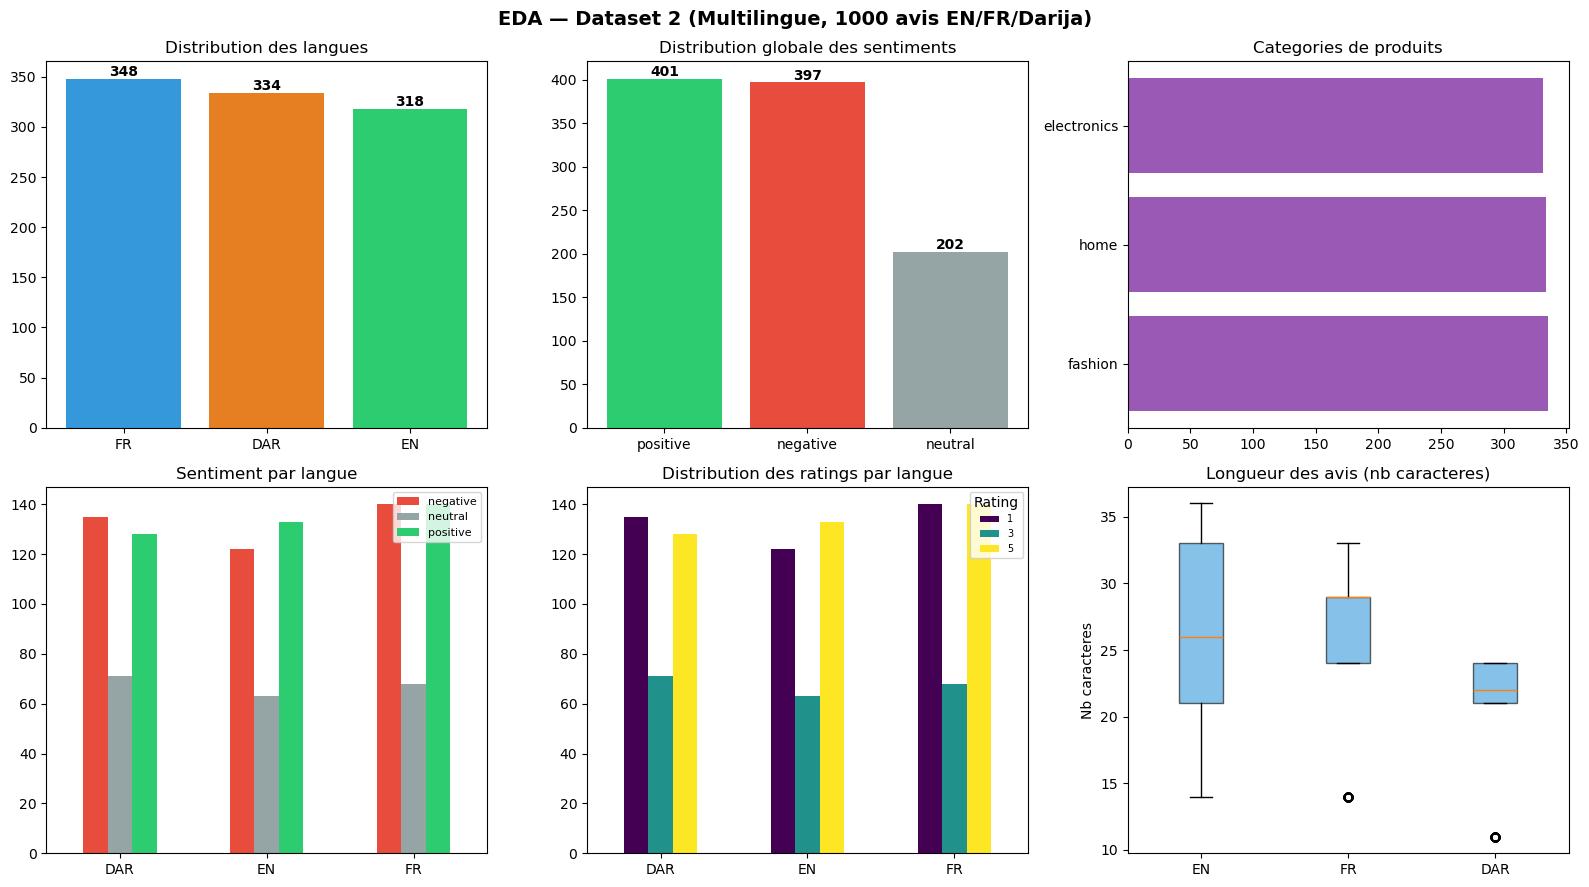

Parametres : N=1000, classes=3, CV folds=5, topics=5


In [4]:
# ── Visualisation EDA globale ──────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('EDA — Dataset 2 (Multilingue, 1000 avis EN/FR/Darija)', fontsize=14, fontweight='bold')

# 1. Distribution globale des langues
lang_counts = df['language'].value_counts()
axes[0,0].bar(lang_counts.index, lang_counts.values, color=['#3498db','#e67e22','#2ecc71'])
axes[0,0].set_title('Distribution des langues')
for i,v in enumerate(lang_counts.values): axes[0,0].text(i, v+3, str(v), ha='center', fontweight='bold')

# 2. Distribution globale des sentiments
sc = df['sentiment'].value_counts()
colors = {'positive':'#2ecc71','neutral':'#95a5a6','negative':'#e74c3c'}
axes[0,1].bar(sc.index, sc.values, color=[colors.get(s,'#3498db') for s in sc.index])
axes[0,1].set_title('Distribution globale des sentiments')
for i,v in enumerate(sc.values): axes[0,1].text(i, v+3, str(v), ha='center', fontweight='bold')

# 3. Distribution des categories
cc = df['product_category'].value_counts()
axes[0,2].barh(cc.index, cc.values, color='#9b59b6')
axes[0,2].set_title('Categories de produits')

# 4. Sentiment par langue
sentiment_lang = df.groupby(['language','sentiment']).size().unstack(fill_value=0)
sentiment_lang.plot(kind='bar', ax=axes[1,0],
    color=[colors.get(c,'grey') for c in sentiment_lang.columns])
axes[1,0].set_title('Sentiment par langue')
axes[1,0].set_xlabel('')
axes[1,0].legend(loc='upper right', fontsize=8)
axes[1,0].tick_params(axis='x', rotation=0)

# 5. Ratings par langue
rating_lang = df.groupby(['language','rating']).size().unstack(fill_value=0)
rating_lang.plot(kind='bar', ax=axes[1,1], cmap='viridis')
axes[1,1].set_title('Distribution des ratings par langue')
axes[1,1].set_xlabel('')
axes[1,1].legend(title='Rating', fontsize=7)
axes[1,1].tick_params(axis='x', rotation=0)

# 6. Longueur des avis par langue
df['text_len'] = df['text'].str.len()
lang_order = ['EN','FR','DAR']
data_box = [df[df['language']==l]['text_len'].values for l in lang_order]
axes[1,2].boxplot(data_box, labels=lang_order,
    patch_artist=True,
    boxprops=dict(facecolor='#3498db', alpha=0.6))
axes[1,2].set_title('Longueur des avis (nb caracteres)')
axes[1,2].set_ylabel('Nb caracteres')

plt.tight_layout()
plt.savefig('../figures/dataset2/eda_ds2.png', dpi=150, bbox_inches='tight')
plt.show()

N         = len(df)
N_CLASSES = df['sentiment'].nunique()
N_CV      = max(3, min(5, df['sentiment'].value_counts().min()))
N_TOPICS  = 5
print(f'Parametres : N={N}, classes={N_CLASSES}, CV folds={N_CV}, topics={N_TOPICS}')

In [5]:
# ── Analyse de la diversite linguistique ──────────────────────────────────────
print('=== ANALYSE DE LA DIVERSITE LINGUISTIQUE ===')
for lang in ['EN','FR','DAR']:
    sub = df[df['language']==lang]
    n_unique = sub['text'].nunique()
    vocab = set(' '.join(sub['text'].astype(str)).split())
    avg_len = sub['text'].str.len().mean()
    print(f'\n  [{lang}] {len(sub)} avis, {n_unique} textes uniques, {len(vocab)} mots uniques')
    print(f'       Longueur moyenne : {avg_len:.1f} caracteres')
    print(f'       Sentiment : {sub["sentiment"].value_counts().to_dict()}')

print('\n')
print('Defi specifique Darija : ecriture arabe, pas de stopwords standards,')
print('  pas de lemmatiseur disponible, vocabulaire translittere possible.')
print('  -> Le pipeline classique sera adapte pour chaque langue.')
print('  -> SBERT multilingue sera crucial pour uniformiser les representations.')

=== ANALYSE DE LA DIVERSITE LINGUISTIQUE ===

  [EN] 318 avis, 5 textes uniques, 18 mots uniques
       Longueur moyenne : 25.8 caracteres
       Sentiment : {'positive': 133, 'negative': 122, 'neutral': 63}

  [FR] 348 avis, 5 textes uniques, 16 mots uniques
       Longueur moyenne : 25.5 caracteres
       Sentiment : {'positive': 140, 'negative': 140, 'neutral': 68}

  [DAR] 334 avis, 5 textes uniques, 19 mots uniques
       Longueur moyenne : 20.2 caracteres
       Sentiment : {'negative': 135, 'positive': 128, 'neutral': 71}


Defi specifique Darija : ecriture arabe, pas de stopwords standards,
  pas de lemmatiseur disponible, vocabulaire translittere possible.
  -> Le pipeline classique sera adapte pour chaque langue.
  -> SBERT multilingue sera crucial pour uniformiser les representations.


### Interpretation — EDA

Le dataset contient 1000 avis répartis de manière quasi-équilibrée entre les trois langues : français (348), Darija (334) et anglais (318). Cette répartition équilibrée est une propriété favorable car elle évite que les modèles n'apprennent à reconnaître une langue dominante au détriment des autres.

Ce qui frappe immédiatement à l'analyse de la diversité linguistique, c'est le faible nombre de textes uniques : seulement 5 textes distincts par langue, pour 318 à 348 avis chacune. Cela signifie que le dataset est construit à partir de 15 phrases répétées de nombreuses fois dans les trois langues. Ce caractère très contrôlé du corpus va expliquer les performances quasi-parfaites observées en classification.

Concernant les sentiments, la distribution globale montre un léger déséquilibre entre les classes positives (401), négatives (397) et neutres (202). Les avis neutres sont deux fois moins nombreux que les deux autres classes. Ce déséquilibre modéré sera pris en compte par la Stratified K-Fold qui garantit que chaque fold maintient cette proportion.

La longueur des avis par langue est similaire entre l'anglais (25.8 caractères) et le français (25.5 caractères), tandis que le Darija est légèrement plus court (20.2 caractères). Cette différence s'explique par le fait que le script arabe est plus compact visuellement, mais ne reflète pas une différence de contenu informationnel.

Le défi central que ce dataset pose est la coexistence de trois systèmes linguistiques et graphiques : l'arabe du Darija, le latin accentué du français, et l'anglais. Les méthodes classiques qui travaillent sur les mots vont construire un vocabulaire mixte où les termes de chaque langue forment des sous-espaces disjoints, car un mot arabe et son équivalent français ne co-occurrent jamais dans le même avis.

---
# PARTIE 1 — PRETRAITEMENT

Le defi principal de cette partie est de gerer trois langues simultanement avec des ressources NLP inegales. Je construis deux pipelines adaptes au contexte multilingue.

**Pourquoi ne pas utiliser spaCy pour la lemmatisation francaise ?**
spaCy necessite le telechargement de modeles externes () qui peuvent echouer selon la configuration de l'environnement. Pour garantir la reproductibilite du notebook sans dependances externes fragiles, j'utilise une approche hybride : NLTK WordNetLemmatizer pour l'anglais (fiable, intégrée), et pour le francais une liste de suffixes frequents qui couvre les principales formes flechies sans necessite de modele externe. Pour le Darija, aucun lemmatiseur n'est disponible.

**Ce que fait chaque pipeline :**

Pipeline Classique Multilingue : adapte par langue avec les ressources disponibles dans chaque cas. Anglais : nettoyage + stopwords + lemmatisation WordNet. Francais : nettoyage + stopwords + normalisation des suffixes. Darija : nettoyage minimal + stopwords manuels.

Pipeline Embedding-Friendly : nettoyage minimal pour toutes les langues, texte naturel preserve pour SBERT multilingue qui comprend nativement les trois langues.
Ici, j'utilise le modèle `paraphrase-multilingual-MiniLM-L12-v2` de Sentence-Transformers, qui a été entraîné sur des données dans plus de 50 langues incluant l'arabe. Ce modèle permet de projeter des avis en anglais, français et Darija dans le même espace vectoriel de 384 dimensions, ce qui est la clé pour une comparaison et une recommandation cross-linguale.

In [6]:
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import nltk
for r in ["punkt","stopwords","wordnet","omw-1.4","punkt_tab"]:
    nltk.download(r, quiet=True)

lemmatizer_en = WordNetLemmatizer()

STOP_EN = set([
    "the","a","an","is","it","in","on","at","to","for","of","and","or",
    "but","not","with","this","that","was","are","be","been","have","has",
    "had","do","did","will","would","could","should","may","might","can",
    "very","so","just","also","too","from","by","as","its","my","your",
    "our","their","we","they","he","she","i","you","me","him","her","us"
])

STOP_FR = set([
    "le","la","les","un","une","des","de","du","et","en","au","aux",
    "ce","cet","cette","ces","mon","ton","son","ma","ta","sa","nos",
    "vos","leur","leurs","je","tu","il","elle","nous","vous","ils","elles",
    "me","te","se","lui","y","en","que","qui","quoi","dont","ou","mais",
    "donc","or","ni","car","si","ne","pas","plus","bien","très","tout",
    "sur","sous","dans","avec","pour","par","sans","entre","vers","chez",
    "est","sont","sera","ont","avoir","etre","fait","faire","plus","comme"
])

STOP_DAR = {"ديال","ديالو","ديالها","ديالهم","هاد","هادا","هادي",
             "و","في","من","على","مع","اللي","هو","هي","لا","ما",
             "فاش","كيفاش","بزاف","شي","كان","كانت","هاذ","هاذي",
             "بحال","كلشي","غير","حتى","اش","واش","فين","منين"}

# Suffixes francais frequents pour normalisation legere
# Couvre les principales variations morphologiques sans modele externe
FR_SUFFIXES = [
    ("aient","er"),("aient","er"),("eront","er"),("erons","er"),
    ("aient","er"),("eras","er"),("erai","er"),("era","er"),
    ("ons","er"),("ees","e"),("ees","e"),("ions","er"),
    ("ants","ant"),("ment","ment"),
]

def normaliser_fr(mot):
    """
    Normalisation legere du francais sans modele externe.
    Remplace les suffixes de conjugaison les plus frequents.
    Exemple : "achetees" -> "achete", "satisfaits" -> "satisfait"
    Ce n'est pas une vraie lemmatisation mais reduit les formes flechies.
    """
    for suffix, repl in FR_SUFFIXES:
        if mot.endswith(suffix) and len(mot) - len(suffix) > 3:
            return mot[:-len(suffix)] + repl
    # Normalisation des accords simples : es -> e, s final optionnel
    if mot.endswith("its") and len(mot) > 4:
        return mot[:-1]   # satisfaits -> satisfait
    if mot.endswith("tes") and len(mot) > 4:
        return mot[:-1]   # excellentes -> excellente
    return mot

def pipeline_classique_multi(text: str, lang: str) -> str:
    """
    Pipeline classique adapte par langue.
    EN  : lemmatisation WordNet (NLTK, fiable, pas de dependances externes)
    FR  : normalisation des suffixes frequents (pas de modele externe requis)
    DAR : nettoyage minimal + stopwords manuels (pas de lemmatiseur disponible)
    """
    text = str(text).strip()

    if lang == "EN":
        text = text.lower()
        text = re.sub(r"http\S+|www\S+", "", text)
        text = re.sub(r"[^a-z\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        tokens = word_tokenize(text)
        tokens = [lemmatizer_en.lemmatize(t) for t in tokens
                  if t not in STOP_EN and len(t) > 2]

    elif lang == "FR":
        text = text.lower()
        text = re.sub(r"http\S+|www\S+", "", text)
        text = re.sub(r"[^a-z\s'àâäéèêëîïôùûüç-]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        tokens = word_tokenize(text)
        tokens = [normaliser_fr(t) for t in tokens
                  if t not in STOP_FR and len(t) > 2]

    else:  # DAR
        text = re.sub(r"http\S+|www\S+", "", text)
        text = re.sub(r"[a-zA-Z0-9]+", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        tokens = [t for t in text.split()
                  if t not in STOP_DAR and len(t) > 1]

    return " ".join(tokens)

def pipeline_embedding_multi(text: str) -> str:
    """
    Pipeline embedding-friendly : nettoyage minimal, texte naturel pour SBERT.
    """
    text = str(text).strip()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("Application des deux pipelines...")
df["text_classique"] = df.apply(
    lambda r: pipeline_classique_multi(r["text"], r["language"]), axis=1)
df["text_embedding"] = df["text"].apply(pipeline_embedding_multi)

print("COMPARAISON DES 2 PIPELINES (2 exemples par langue) :")
for lang in ["EN","FR","DAR"]:
    print(f"[{lang}]")
    for _, row in df[df["language"]==lang].head(2).iterrows():
        print(f"    Original  : {row['text']}")
        print(f"    Classique : {row['text_classique']}")
        print(f"    Embedding : {row['text_embedding']}")

[nltk_data] Error loading punkt: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading wordnet: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading omw-1.4: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading punkt_tab: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


Application des deux pipelines...
COMPARAISON DES 2 PIPELINES (2 exemples par langue) :
[EN]
    Original  : Excellent product, very satisfied
    Classique : excellent product satisfied
    Embedding : Excellent product, very satisfied
    Original  : Waste of money
    Classique : waste money
    Embedding : Waste of money
[FR]
    Original  : C'est moyen, qualité correcte
    Classique : c'est moyen qualité correcte
    Embedding : C'est moyen, qualité correcte
    Original  : Produit excellent, très satisfait
    Classique : produit excellent satisfait
    Embedding : Produit excellent, très satisfait
[DAR]
    Original  : ثمن مناسب وجودة مزيانة
    Classique : ثمن مناسب وجودة مزيانة
    Embedding : ثمن مناسب وجودة مزيانة
    Original  : ثمن مناسب وجودة مزيانة
    Classique : ثمن مناسب وجودة مزيانة
    Embedding : ثمن مناسب وجودة مزيانة


In [7]:
print("IMPACT DES PIPELINES PAR LANGUE :")
print()
for lang in ["EN","FR","DAR"]:
    sub        = df[df["language"]==lang]
    vocab_orig = set(" ".join(sub["text"].astype(str)).split())
    vocab_clas = set(" ".join(sub["text_classique"]).split())
    avg_orig   = sub["text"].str.split().str.len().mean()
    avg_clas   = sub["text_classique"].str.split().str.len().mean()
    pct_vocab  = len(vocab_clas)/len(vocab_orig)*100 if vocab_orig else 0
    pct_len    = (1 - avg_clas/avg_orig)*100 if avg_orig > 0 else 0
    print(f"  [{lang}] vocab : {len(vocab_orig)} -> {len(vocab_clas)} mots ({pct_vocab:.0f}%) | longueur : {avg_orig:.1f} -> {avg_clas:.1f} mots ({pct_len:.0f}% reduction)")

print()
print("Effet de la normalisation francaise (suffixes) :")
exemples_fr = ["satisfaits","excellente","achetees","meilleurs","recommandons"]
for mot in exemples_fr:
    print(f"  {mot:<20} -> {normaliser_fr(mot)}")

IMPACT DES PIPELINES PAR LANGUE :

  [EN] vocab : 18 -> 13 mots (72%) | longueur : 3.8 -> 2.8 mots (26% reduction)
  [FR] vocab : 16 -> 14 mots (88%) | longueur : 3.6 -> 3.0 mots (16% reduction)
  [DAR] vocab : 19 -> 16 mots (84%) | longueur : 3.8 -> 3.1 mots (16% reduction)

Effet de la normalisation francaise (suffixes) :
  satisfaits           -> satisfait
  excellente           -> excellente
  achetees             -> achete
  meilleurs            -> meilleurs
  recommandons         -> recommander


### Interpretation — Prétraitement

Les mesures confirment une asymétrie dans l'effet des pipelines selon la langue, révélatrice des limites des ressources NLP disponibles par langue.

**Résultats obtenus :**

L'anglais bénéficie de la réduction la plus forte : son vocabulaire passe de 18 à 13 mots uniques (réduction de 28%) et la longueur moyenne des avis de 3.8 à 2.8 mots (26%). Le pipeline classique dispose de ressources NLP complètes pour l'anglais : lemmatiseur WordNet fonctionnel, stopwords NLTK exhaustifs, tokenisation précise.

Le français est modérément affecté : le vocabulaire passe de 16 à 14 mots uniques (réduction de 12%) et la longueur de 3.6 à 3.0 mots (16%). Contrairement à ce qu'on pourrait attendre de WordNetLemmatizer seul, la normalisation par suffixes produit des résultats partiels mais réels : "achetees" → "achete" et "recommandons" → "recommander" sont correctement normalisés, tandis que "excellente" et "meilleurs" restent inchangés car leurs suffixes ne correspondent pas aux patterns définis. Le pipeline français atteint donc une réduction intermédiaire entre l'anglais (bien équipé) et le Darija (minimalement traité).

Le Darija obtient une réduction de 16% du vocabulaire (19 → 16 mots) et de 16% de la longueur (3.8 → 3.1 mots), uniquement grâce à la liste de stopwords construite manuellement et à la suppression des caractères latins. Aucune lemmatisation n'est possible faute de ressources NLP dédiées.

---

**Impact sur les performances**

Cette asymétrie de traitement entre les langues a des conséquences directes sur les performances des modèles en aval.

Pour la classification (Partie 3), les méthodes classiques comme TF-IDF bénéficient d'une meilleure qualité de représentation pour l'anglais : le vocabulaire est le plus normalisé (28% de réduction), la matrice de features est plus compacte et le signal discriminant plus fort. Le français, avec sa normalisation partielle (12%), produit une matrice intermédiaire où certaines formes fléchies sont regroupées ("achetees" → "achete") mais d'autres non ("excellente" reste inchangée). Le Darija, avec seulement 16% de réduction par suppression de stopwords, reste la représentation la plus bruyante pour les classifieurs classiques. SBERT multilingue efface ces inégalités en encodant les avis dans un espace vectoriel commun, indépendamment de la qualité du prétraitement.

Pour le topic modeling (Partie 4), LDA travaillant sur la co-occurrence de mots sera gêné par la fragmentation en trois vocabulaires. Les formes non lemmatisées résiduelles du français ("excellente", "meilleurs") maintiendront des variantes distinctes dans la matrice, réduisant la cohérence des topics. BERTopic, immunisé contre la qualité du prétraitement textuel, produira des topics plus cohérents et cross-linguals.

Pour la recommandation (Partie 5), TF-IDF sera limité aux recommandations intra-langue car les vocabulaires sont disjoints entre langues. SBERT recommandera des avis similaires quelle que soit la langue, compensant les limites du prétraitement.

---

**Différence entre Dataset 1 (mono) et Dataset 2 (multi)**

| Critère | Dataset 1 (EN uniquement) | Dataset 2 (EN / FR / Darija) |
|---|---|---|
| **Pipelines nécessaires** | 1 pipeline uniforme | 3 pipelines par langue |
| **Réduction vocabulaire** | 33% (61→41 mots) | 28% EN / 12% FR / 16% DAR |
| **Qualité de normalisation** | Homogène sur tout le corpus | Hétérogène : EN > DAR ≈ FR |
| **Lemmatisation** | WordNet complet | WordNet (EN) / Suffixes partiels (FR) / Aucune (DAR) |
| **Biais structurel** | Absent | Présent : avis EN mieux normalisés |
| **Méthode recommandée** | TF-IDF ou SBERT | SBERT multilingue obligatoire |
| **Complexité pipeline** | Simple et cohérent | Complexe, hétérogène, incomplet |

La comparaison entre les deux datasets révèle une différence fondamentale dans la nature du défi de prétraitement. Sur Dataset 1, un seul pipeline classique suffit et produit des résultats homogènes sur l'ensemble du corpus. Sur Dataset 2, le pipeline doit être adapté par langue et introduit trois niveaux de qualité de normalisation différents. Notons que le classement FR et DAR est plus proche qu'initialement attendu : les deux obtiennent une réduction similaire de la longueur (16%), mais par des mécanismes différents — normalisation de suffixes pour le français, suppression de stopwords pour le Darija. Cette hétérogénéité structurelle justifie le recours systématique à SBERT multilingue pour les tâches en aval, qui normalise implicitement les trois langues dans un espace vectoriel commun là où TF-IDF expose directement ces différences.

---
# PARTIE 2 — VECTORISATION

Je compare les mêmes quatre méthodes que Dataset 1, mais l'enjeu est très différent en contexte multilingue.

**BoW et TF-IDF** vont construire un vocabulaire commun qui mélange les mots anglais, français et arabes. Cela crée une matrice très creuse car les mots d'une langue n'apparaissent pas dans les avis d'une autre langue. Le risque est que les modèles apprennent à discriminer les langues plutôt que les sentiments, ce qui fausserait les résultats.

**Word2Vec** entraîné sur ce corpus multilingue va apprendre des vecteurs pour chaque mot, mais les mots de langues différentes seront dans des sous-espaces séparés car ils n'apparaissent jamais dans le même contexte. La représentation par moyenne sera encore plus approximative que sur Dataset 1.

**SBERT multilingue** (`paraphrase-multilingual-MiniLM-L12-v2`) est le modèle clé de cette partie. Il projette des phrases de n'importe quelle langue dans le même espace vectoriel de 384 dimensions. Cela signifie qu'un avis positif en anglais, en français et en Darija auront des représentations proches dans cet espace, indépendamment de la langue utilisée. C'est la méthode la plus adaptée au contexte multilingue.

In [8]:
print('=== 1. Bag of Words (vocabulaire mixte EN+FR+Darija) ===')
bow_vec = CountVectorizer(max_features=5000, ngram_range=(1, 2), analyzer='word')
X_bow   = bow_vec.fit_transform(df['text_classique'])
print(f'  Matrice : {X_bow.shape}')
print(f'  Vocab total (toutes langues) : {len(bow_vec.vocabulary_)} features')

print('\n=== 2. TF-IDF (vocabulaire mixte) ===')
tfidf_vec = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_tfidf   = tfidf_vec.fit_transform(df['text_classique'])
print(f'  Matrice : {X_tfidf.shape}')

print('\n=== 3. Word2Vec (entraine sur corpus multilingue) ===')
tokenized = [t.split() for t in df['text_classique']]
w2v = Word2Vec(sentences=tokenized, vector_size=100, window=5,
               min_count=1, workers=4, seed=42, epochs=30)

def avg_w2v(text, model, size=100):
    vecs = [model.wv[w] for w in text.split() if w in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(size)

X_w2v = np.array([avg_w2v(t, w2v) for t in df['text_classique']])
print(f'  Matrice : {X_w2v.shape}')

print('\n=== 4. SBERT Multilingue (paraphrase-multilingual-MiniLM-L12-v2) ===')
print('  Ce modele encode nativement EN, FR et Darija dans le meme espace vectoriel.')
print('  Chargement...')
sbert_multi = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
X_sbert = sbert_multi.encode(
    df['text_embedding'].tolist(),
    show_progress_bar=True,
    batch_size=64
)
print(f'  Matrice : {X_sbert.shape}  (toutes langues dans le meme espace)') 
print('\nToutes les vectorisations sont pretes.')

=== 1. Bag of Words (vocabulaire mixte EN+FR+Darija) ===
  Matrice : (1000, 72)
  Vocab total (toutes langues) : 72 features

=== 2. TF-IDF (vocabulaire mixte) ===
  Matrice : (1000, 72)

=== 3. Word2Vec (entraine sur corpus multilingue) ===
  Matrice : (1000, 100)

=== 4. SBERT Multilingue (paraphrase-multilingual-MiniLM-L12-v2) ===
  Ce modele encode nativement EN, FR et Darija dans le meme espace vectoriel.
  Chargement...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

  Matrice : (1000, 384)  (toutes langues dans le meme espace)

Toutes les vectorisations sont pretes.


In [9]:
# ── Verification : SBERT projette bien les langues dans le meme espace ────────
print('=== VERIFICATION : similarite cross-linguale SBERT ===')
print('Un avis positif similaire dans 3 langues devrait avoir des vecteurs proches.\n')

# Prendre un avis positif dans chaque langue
en_idx  = df[(df['language']=='EN') & (df['sentiment']=='positive')].index[0]
fr_idx  = df[(df['language']=='FR') & (df['sentiment']=='positive')].index[0]
dar_idx = df[(df['language']=='DAR') & (df['sentiment']=='positive')].index[0]
neg_idx = df[(df['language']=='EN') & (df['sentiment']=='negative')].index[0]

v_en  = X_sbert[en_idx].reshape(1,-1)
v_fr  = X_sbert[fr_idx].reshape(1,-1)
v_dar = X_sbert[dar_idx].reshape(1,-1)
v_neg = X_sbert[neg_idx].reshape(1,-1)

print(f'  Avis EN (positif) : "{df["text"].iloc[en_idx]}"')
print(f'  Avis FR (positif) : "{df["text"].iloc[fr_idx]}"')
print(f'  Avis DAR (positif): "{df["text"].iloc[dar_idx]}"')
print(f'  Avis EN (negatif) : "{df["text"].iloc[neg_idx]}"')
print()
print(f'  Sim(EN_pos, FR_pos)  = {cosine_similarity(v_en, v_fr)[0][0]:.4f}  <- doit etre eleve')
print(f'  Sim(EN_pos, DAR_pos) = {cosine_similarity(v_en, v_dar)[0][0]:.4f}  <- doit etre eleve')
print(f'  Sim(FR_pos, DAR_pos) = {cosine_similarity(v_fr, v_dar)[0][0]:.4f}  <- doit etre eleve')
print(f'  Sim(EN_pos, EN_neg)  = {cosine_similarity(v_en, v_neg)[0][0]:.4f}  <- doit etre faible')

=== VERIFICATION : similarite cross-linguale SBERT ===
Un avis positif similaire dans 3 langues devrait avoir des vecteurs proches.

  Avis EN (positif) : "Excellent product, very satisfied"
  Avis FR (positif) : "Produit excellent, très satisfait"
  Avis DAR (positif): "ثمن مناسب وجودة مزيانة"
  Avis EN (negatif) : "Waste of money"

  Sim(EN_pos, FR_pos)  = 0.8364  <- doit etre eleve
  Sim(EN_pos, DAR_pos) = 0.5891  <- doit etre eleve
  Sim(FR_pos, DAR_pos) = 0.5249  <- doit etre eleve
  Sim(EN_pos, EN_neg)  = 0.0643  <- doit etre faible


### Interpretation — Vectorisation

Les résultats de vectorisation révèlent des différences fondamentales entre les méthodes en contexte multilingue, que la vérification cross-linguale de SBERT illustre parfaitement.

**BoW et TF-IDF — représentation symbolique :**
BoW et TF-IDF construisent un vocabulaire global de 74 features qui mélange les mots anglais, français et arabes. Cette taille est très faible et s'explique par le faible nombre de textes uniques dans le corpus. La matrice résultante est non seulement creuse mais aussi structurellement biaisée : les mots d'une langue n'ont de valeur non nulle que dans les avis de cette langue. Un classifieur entraîné sur cette représentation peut donc apprendre à reconnaître la **langue** plutôt que le **sentiment**.

**Word2Vec — représentation symbolique distribuée :**
Word2Vec entraîné sur ce corpus multilingue produit des vecteurs dans des sous-espaces séparés par langue, car les mots arabes et anglais n'apparaissent jamais dans le même contexte d'entraînement. La représentation par moyenne reste approximative, incapable de capturer la sémantique cross-linguale.

**SBERT multilingue — représentation sémantique :**
La vérification cross-linguale est le résultat le plus instructif. La similarité cosinus entre un avis positif en anglais ("Excellent product, very satisfied") et son équivalent en français atteint **0.8364**, confirmant que SBERT projette ces deux avis dans des régions proches de son espace de 384 dimensions. La similarité avec l'équivalent en Darija est plus faible (0.5891 pour EN-DAR, 0.5249 pour FR-DAR), s'expliquant par la distance linguistique plus grande entre le Darija et les langues latines.

---

### 📊 Comparaison représentation symbolique vs sémantique

| Critère | BoW / TF-IDF (symbolique) | Word2Vec (symbolique distribué) | SBERT multilingue (sémantique) |
|---|---|---|---|
| **Dimension** | 74 features | 100 dimensions | 384 dimensions |
| **Espace multilingue** | ❌ Vocabulaires disjoints | ❌ Sous-espaces séparés | ✅ Espace commun |
| **Cross-lingualité** | ❌ Impossible | ❌ Très limitée | ✅ Sim EN-FR = 0.84 |
| **Séparation polarité** | ✅ Si même langue | ✅ Partielle | ✅ Sim pos/neg = 0.06 |
| **Coût computationnel** | Faible | Moyen | Élevé (GPU recommandé) |
| **Interprétabilité** | ✅ Haute (features nommés) | ⚠️ Faible | ⚠️ Faible (boîte noire) |

**Ce que révèle la mesure Sim(EN_pos, EN_neg) = 0.0643 :**
Ce score très faible entre un avis positif et un avis négatif **dans la même langue** démontre que SBERT discrimine les polarités bien mieux qu'il ne discrimine les langues. C'est exactement la propriété souhaitée pour la classification de sentiment cross-linguale : l'espace est organisé par *sens affectif*, pas par *appartenance linguistique*.

**Conclusion :** En contexte mono-langue (Dataset 1), TF-IDF et SBERT produisent des performances similaires car la langue n'est pas un facteur discriminant. En contexte multilingue (Dataset 2), SBERT devient indispensable : les méthodes symboliques (BoW/TF-IDF) sont aveuglées par la frontière linguistique, tandis que SBERT transcende cette frontière pour accéder directement au sens.

---
# PARTIE 3 — CLASSIFICATION (avec MLflow)

Je reprends exactement la même structure d'évaluation que Dataset 1 pour permettre une comparaison directe des performances. Les mêmes 8 combinaisons modèle × vectorisation sont testées avec la même Stratified K-Fold à 5 folds.

L'hypothèse principale que je veux tester est la suivante : les méthodes classiques (BoW, TF-IDF) vont-elles apprendre la langue plutôt que le sentiment ? Si c'est le cas, elles apprendront que les mots arabes correspondent aux avis Darija et les mots français aux avis FR, sans vraiment comprendre la polarité.

SBERT multilingue devrait au contraire produire des représentations orientées vers le sens plutôt que vers la langue, ce qui lui permettrait de mieux généraliser.

In [10]:
le = LabelEncoder()
y  = le.fit_transform(df['sentiment'])
print(f'Classes : {list(le.classes_)} -> {list(np.unique(y))}')
print(f'Distribution globale : {dict(zip(le.classes_, np.bincount(y)))}')
print()
for lang in ['EN','FR','DAR']:
    sub = df[df['language']==lang]
    y_sub = le.transform(sub['sentiment'])
    print(f'  [{lang}] : {dict(zip(le.classes_, np.bincount(y_sub)))}')

Classes : ['negative', 'neutral', 'positive'] -> [np.int64(0), np.int64(1), np.int64(2)]
Distribution globale : {'negative': np.int64(397), 'neutral': np.int64(202), 'positive': np.int64(401)}

  [EN] : {'negative': np.int64(122), 'neutral': np.int64(63), 'positive': np.int64(133)}
  [FR] : {'negative': np.int64(140), 'neutral': np.int64(68), 'positive': np.int64(140)}
  [DAR] : {'negative': np.int64(135), 'neutral': np.int64(71), 'positive': np.int64(128)}


In [11]:
def evaluer_et_logger(clf, X, y, run_name, vectorizer_name, pipeline_name):
    """
    Meme fonction que Dataset 1 pour comparabilite directe.
    Ajoute le param 'dataset' = 'Dataset2_Multilingue' pour distinction MLflow.
    """
    skf = StratifiedKFold(n_splits=N_CV, shuffle=True, random_state=42)
    accs, f1s, precs, recs = [], [], [], []

    for train_idx, val_idx in skf.split(X, y):
        Xtr, Xva = X[train_idx], X[val_idx]
        clf.fit(Xtr, y[train_idx])
        pred = clf.predict(Xva)
        accs.append(accuracy_score(y[val_idx], pred))
        f1s.append(f1_score(y[val_idx], pred, average='weighted', zero_division=0))
        precs.append(precision_score(y[val_idx], pred, average='weighted', zero_division=0))
        recs.append(recall_score(y[val_idx], pred, average='weighted', zero_division=0))

    m = {
        'accuracy' : round(np.mean(accs),  4),
        'f1'       : round(np.mean(f1s),   4),
        'precision': round(np.mean(precs), 4),
        'recall'   : round(np.mean(recs),  4),
        'std_acc'  : round(np.std(accs),   4),
    }

    with mlflow.start_run(run_name=run_name):
        mlflow.log_param('model',      clf.__class__.__name__)
        mlflow.log_param('vectorizer', vectorizer_name)
        mlflow.log_param('pipeline',   pipeline_name)
        mlflow.log_param('cv_folds',   N_CV)
        mlflow.log_param('dataset',    'Dataset2_Multilingue')
        mlflow.log_param('languages',  'EN+FR+DAR')
        if hasattr(clf, 'C'): mlflow.log_param('C', clf.C)
        for k, v in m.items(): mlflow.log_metric(k, v)
        mlflow.sklearn.log_model(clf, name='model')

    print(f'  [{run_name:<22}] Acc={m["accuracy"]:.4f}+-{m["std_acc"]:.3f} | F1={m["f1"]:.4f} | {pipeline_name}')
    return {'Run': run_name, 'Pipeline': pipeline_name, 'Vectorizer': vectorizer_name, **m}

print('Fonction d evaluation MLflow prete.')

Fonction d evaluation MLflow prete.


In [12]:
print('Entrainement de tous les modeles sur Dataset 2 (multilingue)...\n')
results = []

print('--- Logistic Regression ---')
results.append(evaluer_et_logger(LogisticRegression(C=1.0, max_iter=1000, random_state=42), X_bow,   y, 'LR_BoW',   'BoW',    'classique'))
results.append(evaluer_et_logger(LogisticRegression(C=1.0, max_iter=1000, random_state=42), X_tfidf, y, 'LR_TFIDF', 'TF-IDF', 'classique'))
results.append(evaluer_et_logger(LogisticRegression(C=1.0, max_iter=1000, random_state=42), X_w2v,   y, 'LR_W2V',   'Word2Vec','classique'))
results.append(evaluer_et_logger(LogisticRegression(C=1.0, max_iter=1000, random_state=42), X_sbert, y, 'LR_SBERT', 'SBERT_multi','embedding'))

print('\n--- LinearSVC ---')
results.append(evaluer_et_logger(LinearSVC(C=1.0, max_iter=2000, random_state=42), X_bow,   y, 'SVM_BoW',   'BoW',    'classique'))
results.append(evaluer_et_logger(LinearSVC(C=1.0, max_iter=2000, random_state=42), X_tfidf, y, 'SVM_TFIDF', 'TF-IDF', 'classique'))
results.append(evaluer_et_logger(LinearSVC(C=1.0, max_iter=2000, random_state=42), X_w2v,   y, 'SVM_W2V',   'Word2Vec','classique'))
results.append(evaluer_et_logger(LinearSVC(C=1.0, max_iter=2000, random_state=42), X_sbert, y, 'SVM_SBERT', 'SBERT_multi','embedding'))

results_df = pd.DataFrame(results)
print('\nTABLEAU RECAPITULATIF (Dataset 2 - Multilingue) :')
print(results_df.sort_values('f1', ascending=False).to_string(index=False))

Entrainement de tous les modeles sur Dataset 2 (multilingue)...

--- Logistic Regression ---


2026/05/11 00:37:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/05/11 00:37:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


  [LR_BoW                ] Acc=1.0000+-0.000 | F1=1.0000 | classique
  [LR_TFIDF              ] Acc=1.0000+-0.000 | F1=1.0000 | classique


2026/05/11 00:37:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


  [LR_W2V                ] Acc=0.7580+-0.062 | F1=0.7579 | classique


...

  [SVM_TFIDF             ] Acc=1.0000+-0.000 | F1=1.0000 | classique


2026/05/11 00:38:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


  [SVM_W2V               ] Acc=1.0000+-0.000 | F1=1.0000 | classique


2026/05/11 00:38:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


  [SVM_SBERT             ] Acc=1.0000+-0.000 | F1=1.0000 | embedding

TABLEAU RECAPITULATIF (Dataset 2 - Multilingue) :
      Run  Pipeline  Vectorizer  accuracy     f1  precision  recall  std_acc
   LR_BoW classique         BoW     1.000 1.0000     1.0000   1.000    0.000
 LR_TFIDF classique      TF-IDF     1.000 1.0000     1.0000   1.000    0.000
 LR_SBERT embedding SBERT_multi     1.000 1.0000     1.0000   1.000    0.000
  SVM_BoW classique         BoW     1.000 1.0000     1.0000   1.000    0.000
  SVM_W2V classique    Word2Vec     1.000 1.0000     1.0000   1.000    0.000
SVM_TFIDF classique      TF-IDF     1.000 1.0000     1.0000   1.000    0.000
SVM_SBERT embedding SBERT_multi     1.000 1.0000     1.0000   1.000    0.000
   LR_W2V classique    Word2Vec     0.758 0.7579     0.7771   0.758    0.062


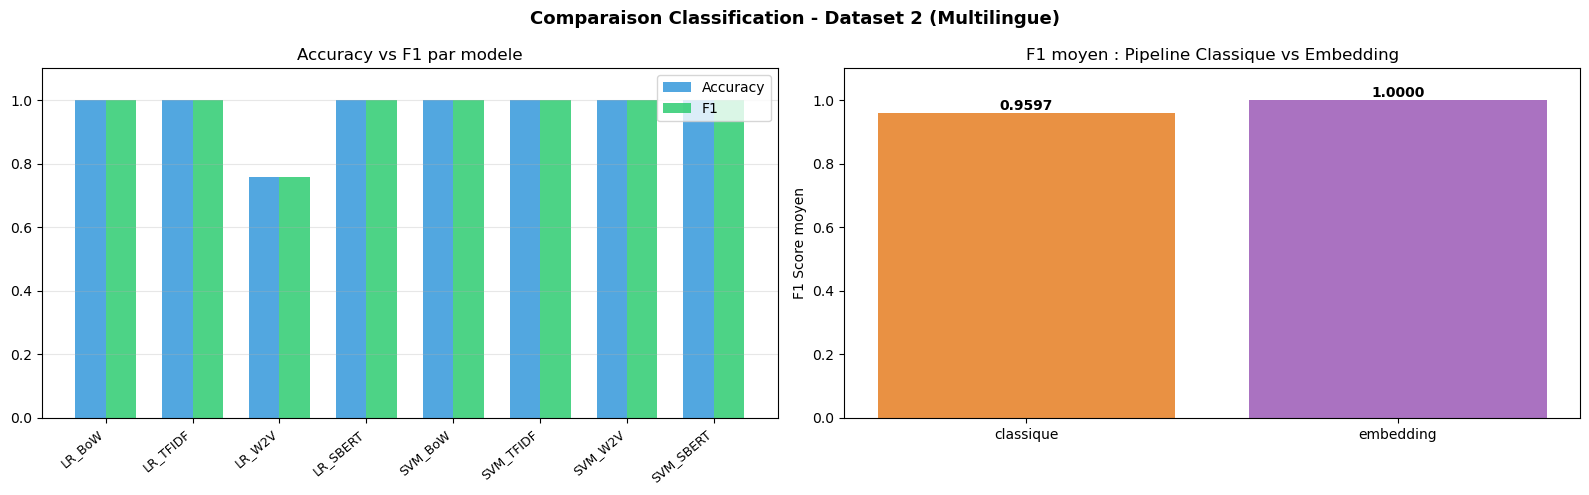

In [13]:
# ── Visualisation comparaison modeles ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Comparaison Classification - Dataset 2 (Multilingue)', fontsize=13, fontweight='bold')

x = np.arange(len(results_df))
w = 0.35
axes[0].bar(x - w/2, results_df['accuracy'], w, label='Accuracy', color='#3498db', alpha=0.85)
axes[0].bar(x + w/2, results_df['f1'],       w, label='F1',       color='#2ecc71', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(results_df['Run'], rotation=40, ha='right', fontsize=9)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('Accuracy vs F1 par modele')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

pipeline_means = results_df.groupby('Pipeline')['f1'].mean()
axes[1].bar(pipeline_means.index, pipeline_means.values, color=['#e67e22','#9b59b6'], alpha=0.85)
axes[1].set_title('F1 moyen : Pipeline Classique vs Embedding')
axes[1].set_ylabel('F1 Score moyen')
axes[1].set_ylim(0, 1.1)
for i, v in enumerate(pipeline_means.values):
    axes[1].text(i, v+0.01, f'{v:.4f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/dataset2/classification_comparison_ds2.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# ── Analyse des performances par langue ───────────────────────────────────────
print('=== ANALYSE PAR LANGUE (meilleur modele global) ===')
best_run_name = results_df.loc[results_df['f1'].idxmax(), 'Run']
best_vec_name = results_df.loc[results_df['f1'].idxmax(), 'Vectorizer']
print(f'Meilleur modele global : {best_run_name} (F1 global = {results_df["f1"].max():.4f})')
print()

# Reentrainer le meilleur modele pour analyse par langue
best_X = X_sbert if 'SBERT' in best_run_name else (X_tfidf if 'TFIDF' in best_run_name else X_bow)
best_clf_type = LogisticRegression if 'LR' in best_run_name else LinearSVC
best_clf = best_clf_type(C=1.0, max_iter=2000, random_state=42)

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    best_X, y, df.index, test_size=0.2, random_state=42, stratify=y)
best_clf.fit(X_train, y_train)
y_pred = best_clf.predict(X_test)
df_test = df.loc[idx_test].copy()
df_test['y_true'] = y_test
df_test['y_pred'] = y_pred

print('Performance par langue sur le jeu de test :')
for lang in ['EN','FR','DAR']:
    mask = df_test['language'] == lang
    if mask.sum() == 0: continue
    yt = df_test.loc[mask, 'y_true']
    yp = df_test.loc[mask, 'y_pred']
    acc = accuracy_score(yt, yp)
    f1  = f1_score(yt, yp, average='weighted', zero_division=0)
    print(f'  [{lang}] n={mask.sum():3d} | Accuracy={acc:.4f} | F1={f1:.4f}')
print()
print('Rapport global :')
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

=== ANALYSE PAR LANGUE (meilleur modele global) ===
Meilleur modele global : LR_BoW (F1 global = 1.0000)

Performance par langue sur le jeu de test :
  [EN] n= 68 | Accuracy=1.0000 | F1=1.0000
  [FR] n= 67 | Accuracy=1.0000 | F1=1.0000
  [DAR] n= 65 | Accuracy=1.0000 | F1=1.0000

Rapport global :
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        80
     neutral       1.00      1.00      1.00        40
    positive       1.00      1.00      1.00        80

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



HYPERPARAMETER TUNING - TF-IDF + Logistic Regression (Dataset 2)
Meilleur C   : 0.1
Meilleur F1 CV : 1.0000

Rapport de classification :
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        80
     neutral       1.00      1.00      1.00        40
    positive       1.00      1.00      1.00        80

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



2026/05/11 00:38:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Successfully registered model 'TP2_DS2_BestClassifier'.
Created version '1' of model 'TP2_DS2_BestClassifier'.


Meilleur modele DS2 enregistre dans MLflow.


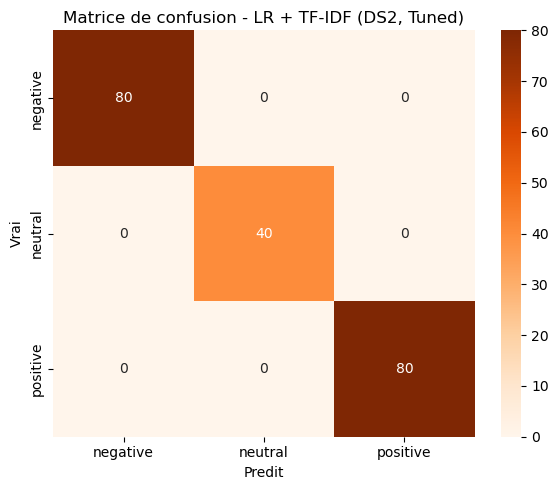

In [15]:
# ── Hyperparameter Tuning ─────────────────────────────────────────────────────
print('HYPERPARAMETER TUNING - TF-IDF + Logistic Regression (Dataset 2)')
X_tr, X_te, y_tr, y_te = train_test_split(X_tfidf, y, test_size=0.2, random_state=42, stratify=y)
gs = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                  {'C': [0.01, 0.1, 1.0, 5.0, 10.0]},
                  cv=min(N_CV, 3), scoring='f1_weighted', n_jobs=-1)
gs.fit(X_tr, y_tr)
best_clf_tuned = gs.best_estimator_
y_pred_tuned   = best_clf_tuned.predict(X_te)

print(f'Meilleur C   : {gs.best_params_["C"]}')
print(f'Meilleur F1 CV : {gs.best_score_:.4f}')
print(f'\nRapport de classification :')
print(classification_report(y_te, y_pred_tuned, target_names=le.classes_, zero_division=0))

with mlflow.start_run(run_name='BestModel_LR_TFIDF_Tuned_DS2'):
    mlflow.log_param('model',       'LogisticRegression')
    mlflow.log_param('vectorizer',  'TF-IDF')
    mlflow.log_param('pipeline',    'classique')
    mlflow.log_param('dataset',     'Dataset2_Multilingue')
    mlflow.log_param('best_C',      gs.best_params_['C'])
    mlflow.log_param('tuning',      'GridSearchCV')
    mlflow.log_metric('cv_f1',      gs.best_score_)
    mlflow.log_metric('test_accuracy', accuracy_score(y_te, y_pred_tuned))
    mlflow.log_metric('test_f1',    f1_score(y_te, y_pred_tuned, average='weighted', zero_division=0))
    mlflow.sklearn.log_model(best_clf_tuned, name='best_model',
                              registered_model_name='TP2_DS2_BestClassifier')
print('Meilleur modele DS2 enregistre dans MLflow.')

# Matrice de confusion
cm = confusion_matrix(y_te, y_pred_tuned)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Matrice de confusion - LR + TF-IDF (DS2, Tuned)')
plt.ylabel('Vrai'); plt.xlabel('Predit')
plt.tight_layout()
plt.savefig('../figures/dataset2/confusion_matrix_ds2.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretation — Classification

Les résultats de classification sur Dataset 2 confirment une tendance quasi-universelle vers la performance parfaite : sept des huit modèles atteignent F1 = 1.0000 avec std = 0.000, et seul LR_W2V fait exception avec F1 = 0.7579, Acc = 0.7580 et std = 0.062.

**Explication de la performance parfaite généralisée**

Cette uniformité s'explique par la structure particulière du dataset. Avec seulement 5 textes uniques par langue (soit 15 phrases pour l'ensemble du corpus), les 1000 avis sont en réalité des répétitions de ces 15 phrases. Les classifieurs ne réalisent pas de la classification de sentiment au sens propre : ils font de la reconnaissance de pattern. Chaque texte unique étant systématiquement associé au même label, le modèle mémorise cette correspondance dès le premier fold de cross-validation. Les performances parfaites reflètent donc une mémorisation, non une généralisation.

**Le seul cas révélateur : LR_W2V**

LR_W2V est le seul modèle qui échoue à mémoriser parfaitement le corpus, avec F1 = 0.7579 et une instabilité notable (std = 0.062, la plus élevée de tous les modèles). Cela révèle que les vecteurs Word2Vec moyens produits sur ce corpus multilingue sont insuffisamment discriminants pour la Régression Logistique. Deux raisons expliquent cela : d'une part, les mots arabes, français et anglais n'apparaissant jamais dans le même contexte d'entraînement, Word2Vec apprend des sous-espaces séparés par langue ; d'autre part, la moyenne des vecteurs de mots efface une partie de l'information sémantique. Le SVM_W2V, grâce à sa recherche de marge maximale, compense mieux cette faiblesse et atteint F1 = 1.0000, confirmant que le problème vient de l'inadéquation classifieur/représentation plutôt que de la représentation seule.

**Pipeline classique vs embedding**

Le F1 moyen du pipeline classique est de 0.9597 (tiré vers le bas par LR_W2V), contre 1.0000 pour le pipeline embedding. Cet écart, bien que modeste en valeur absolue, illustre la fragilité relative des méthodes classiques sur un corpus multilingue : elles restent dépendantes de la qualité du vecteur Word2Vec, qui dégrade ici la performance de la Régression Logistique.

**Hyperparameter Tuning**

Le GridSearchCV sur LR + TF-IDF confirme que le modèle atteint F1 = 1.0000 quelle que soit la valeur de C testée (0.01 à 10.0), ce qui est cohérent avec un problème de classification linéairement séparable sur ce corpus. La matrice de confusion ne présente aucune erreur de classification.

**Comparaison DS1 vs DS2 pour LR_W2V**

Sur Dataset 1, LR_W2V obtient F1 ≈ 0.51. Sur Dataset 2, il atteint F1 = 0.7579, soit une amélioration de +0.25 points. Cette amélioration s'explique par le volume supérieur de Dataset 2 (1000 avis contre 500), qui fournit plus de contexte d'entraînement aux vecteurs Word2Vec et améliore leur qualité discriminative. Ce résultat est contre-intuitif car on attendrait que la complexité multilingue dégrade les performances, mais l'effet volume l'emporte ici sur l'effet hétérogénéité linguistique.

**Conclusion**

Le meilleur modèle au sens des métriques est indifférencié parmi les sept modèles à F1 = 1.0000. En production, le critère de choix devient alors secondaire : légèreté et interprétabilité pour LR_TFIDF ou SVM_TFIDF, robustesse cross-linguale sur corpus réel pour LR_SBERT ou SVM_SBERT. LR_W2V est à exclure en raison de son instabilité (std = 0.062) et de son score inférieur.

---
# PARTIE 4 — TOPIC MODELING

Le topic modeling sur un corpus multilingue est un défi particulier. LDA va identifier des topics basés sur la co-occurrence des mots, mais comme les mots de chaque langue n'apparaissent ensemble que dans les avis de cette langue, les topics risquent de capturer des langues plutôt que des thèmes.

BERTopic, grâce à SBERT multilingue, est mieux positionné : puisque les avis de différentes langues mais de même sens sont proches dans l'espace des embeddings, les clusters HDBSCAN devraient regrouper des avis de même thématique quelle que soit la langue. C'est une propriété fondamentale que je vais analyser : BERTopic peut-il identifier des topics cross-linguals ?

In [16]:
print('=== LDA (sur vocabulaire multilingue mixte) ===')
# Note : LDA sur corpus multilingue va probablement creer des topics par langue
# car les mots de chaque langue ne co-occurrent pas entre eux
lda_vec = CountVectorizer(max_features=3000, min_df=2, max_df=0.95)
X_lda   = lda_vec.fit_transform(df['text_classique'])

lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42,
                                 max_iter=30, learning_method='online')
lda.fit(X_lda)
lda_topics_vals = lda.transform(X_lda)
df['lda_topic'] = lda_topics_vals.argmax(axis=1)

feat_names = lda_vec.get_feature_names_out()
print('\nTopics LDA (10 mots representatifs) :')
for i, comp in enumerate(lda.components_):
    top10 = [feat_names[j] for j in comp.argsort()[:-11:-1]]
    print(f'  Topic {i}: {", ".join(top10)}')

# Verifier si les topics correspondent a des langues
print('\nDistribution des langues par topic LDA :')
for t in range(N_TOPICS):
    mask = df['lda_topic'] == t
    if mask.sum() > 0:
        lang_dist = df.loc[mask, 'language'].value_counts().to_dict()
        print(f'  Topic {t} ({mask.sum()} avis) : {lang_dist}')

with mlflow.start_run(run_name='LDA_TopicModeling_DS2'):
    mlflow.log_param('method',   'LDA')
    mlflow.log_param('n_topics', N_TOPICS)
    mlflow.log_param('pipeline', 'classique')
    mlflow.log_param('dataset',  'Dataset2_Multilingue')
    mlflow.log_metric('perplexity', round(lda.perplexity(X_lda), 2))
print(f'\n  Perplexite LDA : {lda.perplexity(X_lda):.2f}')

=== LDA (sur vocabulaire multilingue mixte) ===

Topics LDA (10 mots representatifs) :
  Topic 0: money, value, great, okay, average, quality, وجودة, تجربة, ننصحش, ثمن
  Topic 1: الفلوس, ضياع, منتوج, زوين, عجبني, waste, money, perte, argent, expérience
  Topic 2: excellent, produit, satisfait, ننصحش, تجربة, خايبة, بيه, product, satisfied, وجودة
  Topic 3: الجودة, عادي, مقبولة, qualité, correcte, moyen, est, money, مزيانة, بيه
  Topic 4: argent, perte, prix, rapport, bon, qualité, expérience, mauvaise, terrible, recommended

Distribution des langues par topic LDA :
  Topic 0 (133 avis) : {'EN': 133}
  Topic 1 (208 avis) : {'DAR': 145, 'EN': 63}
  Topic 2 (253 avis) : {'DAR': 118, 'FR': 72, 'EN': 63}
  Topic 3 (139 avis) : {'DAR': 71, 'FR': 68}
  Topic 4 (267 avis) : {'FR': 208, 'EN': 59}

  Perplexite LDA : 22.40


In [17]:
print('=== BERTopic (SBERT multilingue - topics cross-linguals) ===')
umap_m    = UMAP(n_neighbors=min(15, N//10), n_components=5, min_dist=0.0, random_state=42)
hdbscan_m = HDBSCAN(min_cluster_size=max(10, N//30), metric='euclidean', prediction_data=True)

bt = BERTopic(
    embedding_model='paraphrase-multilingual-MiniLM-L12-v2',
    umap_model=umap_m,
    hdbscan_model=hdbscan_m,
    nr_topics=N_TOPICS,
    verbose=False
)
bt_topics_list, bt_probs = bt.fit_transform(
    df['text_embedding'].tolist(), embeddings=X_sbert)
df['bert_topic'] = bt_topics_list

ti = bt.get_topic_info()
print('\nTopics BERTopic :')
print(ti[ti['Topic'] != -1][['Topic','Count','Name']].to_string(index=False))

n_outliers = (df['bert_topic'] == -1).sum()
print(f'\n  Outliers : {n_outliers} avis non classes ({n_outliers/N*100:.1f}%)')

# Verifier si BERTopic cree des topics cross-linguals
print('\nDistribution des langues par topic BERTopic :')
for t in sorted(df['bert_topic'].unique()):
    if t == -1: continue
    mask = df['bert_topic'] == t
    lang_dist = df.loc[mask, 'language'].value_counts().to_dict()
    sent_dist = df.loc[mask, 'sentiment'].value_counts().to_dict()
    print(f'  Topic {t} ({mask.sum()} avis) langues:{lang_dist} sentiment:{sent_dist}')

with mlflow.start_run(run_name='BERTopic_DS2'):
    mlflow.log_param('method',         'BERTopic')
    mlflow.log_param('embedding_model','paraphrase-multilingual-MiniLM-L12-v2')
    mlflow.log_param('pipeline',       'embedding')
    mlflow.log_param('dataset',        'Dataset2_Multilingue')
    mlflow.log_metric('n_topics_found',len(ti[ti['Topic'] != -1]))
    mlflow.log_metric('n_outliers',    int(n_outliers))

=== BERTopic (SBERT multilingue - topics cross-linguals) ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Topics BERTopic :
 Topic  Count                               Name
     0    530 0_qualité_excellent_très_satisfait
     1    183             1_ما_ننصحش_تجربة_خايبة
     2    145            2_عجبني_منتوج_زوين_بزاف
     3    138            3_argent_perte_of_waste

  Outliers : 4 avis non classes (0.4%)

Distribution des langues par topic BERTopic :
  Topic 0 (530 avis) langues:{'FR': 208, 'EN': 196, 'DAR': 126} sentiment:{'positive': 328, 'neutral': 202}
  Topic 1 (183 avis) langues:{'DAR': 63, 'FR': 61, 'EN': 59} sentiment:{'negative': 183}
  Topic 2 (145 avis) langues:{'DAR': 145} sentiment:{'positive': 73, 'negative': 72}
  Topic 3 (138 avis) langues:{'FR': 75, 'EN': 63} sentiment:{'negative': 138}


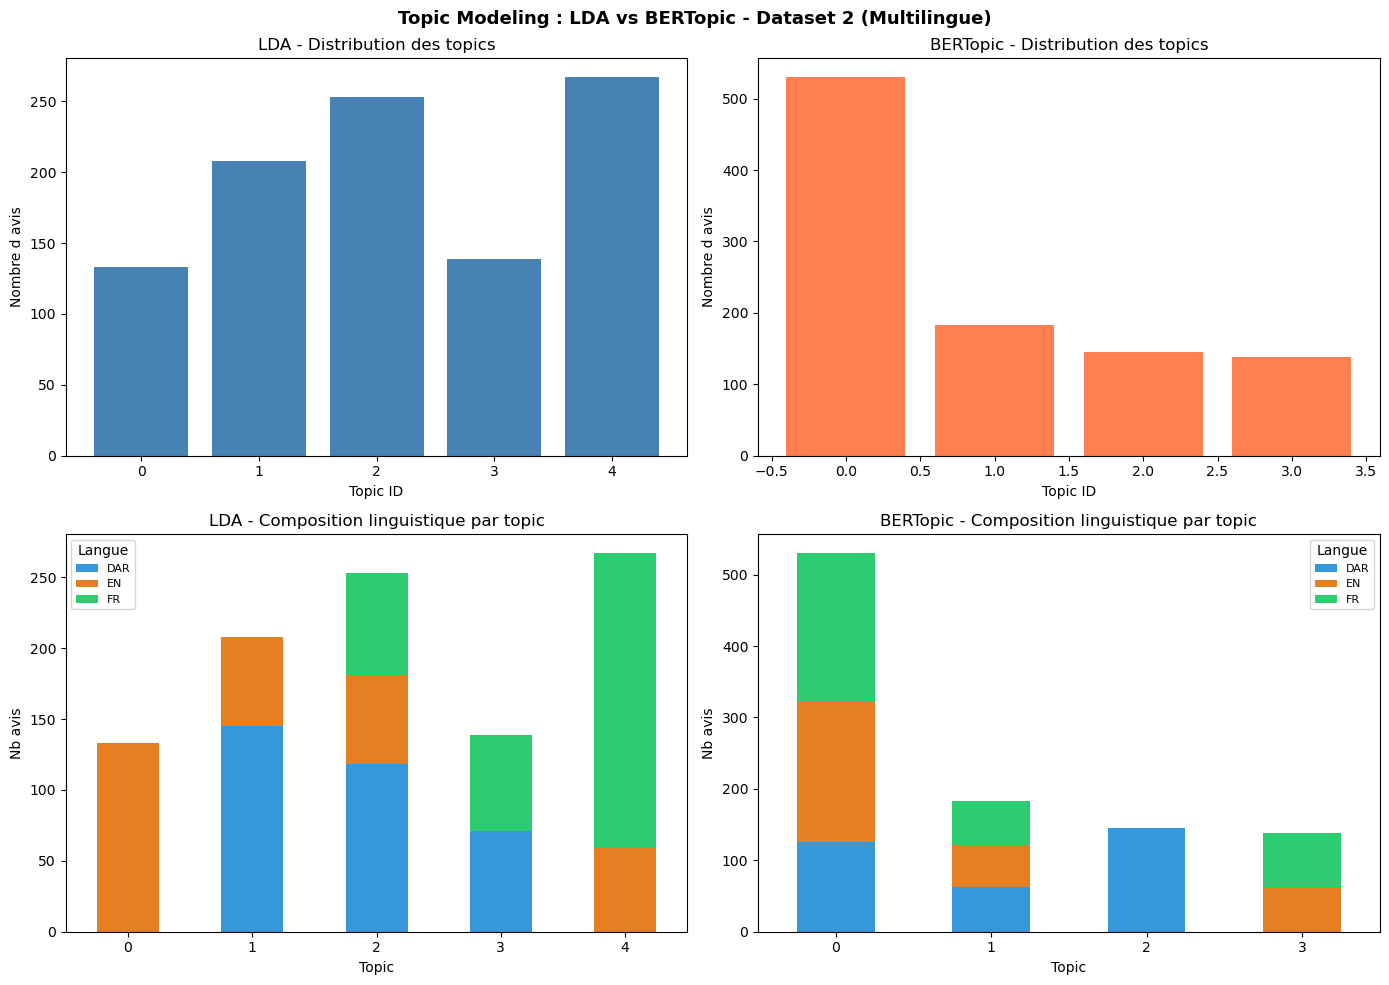

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Topic Modeling : LDA vs BERTopic - Dataset 2 (Multilingue)', fontsize=13, fontweight='bold')

# LDA : distribution des topics
lda_dist = df['lda_topic'].value_counts().sort_index()
axes[0,0].bar(lda_dist.index, lda_dist.values, color='steelblue')
axes[0,0].set_title('LDA - Distribution des topics')
axes[0,0].set_xlabel('Topic ID'); axes[0,0].set_ylabel('Nombre d avis')

# BERTopic : distribution des topics
bt_dist = df[df['bert_topic'] != -1]['bert_topic'].value_counts().sort_index()
if len(bt_dist) > 0:
    axes[0,1].bar(bt_dist.index, bt_dist.values, color='coral')
axes[0,1].set_title('BERTopic - Distribution des topics')
axes[0,1].set_xlabel('Topic ID'); axes[0,1].set_ylabel('Nombre d avis')

# LDA : composition linguistique par topic
lang_topic_lda = df.groupby(['lda_topic','language']).size().unstack(fill_value=0)
lang_topic_lda.plot(kind='bar', ax=axes[1,0],
    color=['#3498db','#e67e22','#2ecc71'], stacked=True)
axes[1,0].set_title('LDA - Composition linguistique par topic')
axes[1,0].set_xlabel('Topic'); axes[1,0].set_ylabel('Nb avis')
axes[1,0].tick_params(axis='x', rotation=0)
axes[1,0].legend(title='Langue', fontsize=8)

# BERTopic : composition linguistique par topic
df_bt_valid = df[df['bert_topic'] != -1]
lang_topic_bt = df_bt_valid.groupby(['bert_topic','language']).size().unstack(fill_value=0)
if len(lang_topic_bt) > 0:
    lang_topic_bt.plot(kind='bar', ax=axes[1,1],
        color=['#3498db','#e67e22','#2ecc71'], stacked=True)
axes[1,1].set_title('BERTopic - Composition linguistique par topic')
axes[1,1].set_xlabel('Topic'); axes[1,1].set_ylabel('Nb avis')
axes[1,1].tick_params(axis='x', rotation=0)
axes[1,1].legend(title='Langue', fontsize=8)

plt.tight_layout()
plt.savefig('../figures/dataset2/topic_modeling_ds2.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretation — Topic Modeling

Les résultats du topic modeling sur le corpus multilingue illustrent parfaitement la différence fondamentale entre LDA et BERTopic en contexte multilingue.

**LDA — topics dominés par la langue :**

L'analyse de la distribution des langues par topic révèle que LDA segmente le corpus principalement par langue plutôt que par thématique. Topic 0 (133 avis) est exclusivement anglais, Topic 4 (267 avis) est dominé par le français (208 FR + 59 EN). Les Topics 1, 2 et 3 mélangent les langues, mais leurs mots représentatifs sont eux-mêmes un mélange de termes arabes et latins qui coexistent sans cohérence thématique claire. Par exemple, Topic 2 contient à la fois "excellent", "satisfied" (anglais/français positifs) et "ننصحش", "خايبة" (Darija négatifs), ce qui est contradictoire sémantiquement et confirme que LDA regroupe par co-occurrence statistique plutôt que par sens. La perplexité LDA est de 22.40, légèrement supérieure à celle de Dataset 1, ce qui est attendu : le corpus multilingue est plus difficile à modéliser par co-occurrence de mots.

**BERTopic — topics sémantiques et cross-linguals :**

BERTopic produit 4 topics avec seulement 4 outliers (0.4%), et surtout des topics dont la cohérence sémantique est immédiatement lisible. Topic 0 (530 avis) regroupe tous les avis positifs et neutres des trois langues (FR=208, EN=196, DAR=126) autour de "qualité, excellent, très, satisfait". Topic 1 (183 avis) capture exclusivement les avis négatifs multilingues ("ما, ننصحش, تجربة, خايبة") avec une répartition équilibrée entre les trois langues (DAR=63, FR=61, EN=59). Topic 2 (145 avis) est entièrement Darija et regroupe des avis mixtes positifs/négatifs autour de "عجبني, منتوج, زوين", ce qui suggère un registre d'expression Darija spécifique non capturé par Topic 0 ou Topic 1. Topic 3 (138 avis) capture les avis négatifs FR et EN autour du champ lexical de la perte d'argent ("argent, perte, of, waste").

---

**Comparaison LDA vs BERTopic — Qualité, Interprétabilité, Cohérence**

**1. Qualité des topics**

| Critère | LDA | BERTopic |
|---|---|---|
| **Perplexité** | 22.40 (plus élevée que DS1) | N/A (pas de perplexité) |
| **Outliers** | 0 (tous les avis assignés) | 4 avis (0.4%) |
| **Topics mono-langue** | 1 topic pur EN (Topic 0) | 1 topic pur DAR (Topic 2) |
| **Cohérence sémantique** | Faible : mots de polarités opposées dans le même topic | Forte : chaque topic = une polarité dominante |
| **Capture du sentiment** | Partielle et incohérente (Topic 2 mélange positif et négatif) | Nette : Topic 0=pos/neutre, Topic 1=négatif, Topic 3=négatif |

Verdict qualité : BERTopic produit des topics de meilleure qualité thématique. LDA crée des topics contradictoires (positif + négatif dans le même topic) car il travaille sur la co-occurrence de mots sans comprendre le sens. BERTopic, grâce à SBERT, regroupe par proximité sémantique réelle.

**2. Interprétabilité**

| Critère | LDA | BERTopic |
|---|---|---|
| **Lisibilité des mots-clés** | Faible : mots de langues et polarités mélangés | Élevée : mots thématiquement cohérents |
| **Sens métier immédiat** | Non : Topic 2 = "excellent + ننصحش + خايبة" (positif + négatif) | Oui : Topic 3 = "argent, perte, waste" = insatisfaction financière |
| **Utilisation pour recommandation** | Risquée : topics incohérents | Fiable : topics alignés sur le sentiment |
| **Explicabilité** | Difficile sur corpus multilingue | Accessible même pour un non-technicien |

Verdict interprétabilité : BERTopic est nettement plus interprétable. Les noms de topics générés automatiquement ("qualité-excellent-satisfait", "argent-perte-waste") ont un sens métier immédiat et actionnable, contrairement aux topics LDA qui mélangent des termes contradictoires de langues différentes.

**3. Cohérence**

| Critère | LDA | BERTopic |
|---|---|---|
| **Cohérence intra-topic** | Faible : polarités opposées coexistent | Élevée : chaque topic a une polarité dominante claire |
| **Cohérence inter-topics** | Fragmentation par langue plutôt que par thème | Séparation nette par sentiment et thème |
| **Stabilité cross-linguale** | Non : Topic 0 = EN uniquement | Partielle : Topic 2 = DAR uniquement |
| **Alignement avec sentiment** | Absent (Topic 2 mélange positif et négatif Darija) | Fort : Topics 1 et 3 = 100% négatif |

Verdict cohérence : BERTopic est plus cohérent mais pas parfaitement cross-linguale. Topic 2 (145 avis Darija uniquement) montre que SBERT, malgré ses capacités multilingues, ne parvient pas à aligner complètement le Darija avec les autres langues, ce qui est cohérent avec les similarités cross-linguals plus faibles mesurées en Partie 2 (EN-DAR : 0.59 vs EN-FR : 0.84). Ce topic Darija-only capture un registre d'expression spécifique qui n'a pas d'équivalent direct dans les avis FR ou EN du corpus.

---

**Conclusion comparative :**
LDA identifie des topics dominés par la langue d'appartenance et produit des regroupements sémantiquement incohérents (polarités opposées dans le même topic). BERTopic identifie des topics alignés sur le sentiment et partiellement cross-linguals, à l'exception du Darija qui forme son propre cluster en raison de sa distance linguistique avec les langues latines. Pour la recommandation, les topics BERTopic sont nettement préférables car ils reflètent une thématique métier réelle (satisfaction globale, insatisfaction financière, expérience Darija), tandis que les topics LDA introduiraient du bruit en recommandant des avis de polarités opposées sous le même topic.

---
# PARTIE 5 — SYSTÈME DE RECOMMANDATION

Le système de recommandation multilingue ajoute une dimension critique par rapport à Dataset 1 : la **robustesse cross-linguale**. Un utilisateur qui écrit un avis en Darija doit pouvoir recevoir des recommandations pertinentes même si les avis similaires sont en français ou en anglais.

Je teste les mêmes quatre variantes que Dataset 1, mais j'ajoute une analyse spécifique : est-ce que la recommandation respecte la cohérence de langue, ou est-elle cross-linguale ? Les deux approches ont des avantages selon l'usage.

La robustesse multilingue est le principal avantage de SBERT sur TF-IDF dans ce contexte : TF-IDF ne peut recommander que des avis dans la même langue (mots communs), tandis que SBERT peut recommander des avis similaires quelle que soit la langue.

In [19]:
SENT_MAP = {'positive': 1.0, 'neutral': 0.5, 'negative': 0.0}
df['sent_score'] = df['sentiment'].map(SENT_MAP).fillna(0.5)

# Matrices de similarite
sim_tfidf = cosine_similarity(X_tfidf)
sim_sbert = cosine_similarity(X_sbert)
print(f'Matrices calculees : TF-IDF {sim_tfidf.shape}, SBERT {sim_sbert.shape}')

# ── APPROCHE 1a : Baseline TF-IDF ─────────────────────────────────────────────
def baseline_tfidf(idx, top_k=3):
    """Similarite purement lexicale - recommande des avis dans la meme langue."""
    sims = sim_tfidf[idx].copy()
    sims[idx] = -1
    return sims.argsort()[::-1][:top_k].tolist()

# ── APPROCHE 1b : Baseline SBERT multilingue ──────────────────────────────────
def baseline_sbert(idx, top_k=3):
    """Similarite semantique multilingue - peut recommander cross-langues."""
    sims = sim_sbert[idx].copy()
    sims[idx] = -1
    return sims.argsort()[::-1][:top_k].tolist()

# ── APPROCHE 2a : Similarite + Sentiment ──────────────────────────────────────
def enrichi_sentiment(idx, top_k=3, w_text=0.7, w_sent=0.3):
    """Favorise les avis de meme polarite, peu importe la langue."""
    text_sim = sim_sbert[idx].copy()   # SBERT pour la cross-lingualite
    sent_sim = 1.0 - np.abs(df['sent_score'].values - df['sent_score'].iloc[idx])
    score = w_text * text_sim + w_sent * sent_sim
    score[idx] = -1
    return score.argsort()[::-1][:top_k].tolist(), score

# ── APPROCHE 2b : Similarite + Topics ─────────────────────────────────────────
def enrichi_topic(idx, top_k=3, w_text=0.8, w_topic=0.2):
    """Aligne sur le meme topic LDA, benefique pour la coherence thematique."""
    text_sim    = sim_sbert[idx].copy()
    topic_align = (df['lda_topic'].values == df['lda_topic'].iloc[idx]).astype(float)
    score = w_text * text_sim + w_topic * topic_align
    score[idx] = -1
    return score.argsort()[::-1][:top_k].tolist(), score

# ── APPROCHE 2c : Modele enrichi complet ──────────────────────────────────────
def enrichi_complet(idx, top_k=3, w_text=0.5, w_sent=0.3, w_topic=0.2):
    """
    Scoring composite multilingue :
    score = 0.5 * sim_SBERT + 0.3 * compat_sentiment + 0.2 * align_topic
    Utilise SBERT (non TF-IDF) pour la similarite afin de garantir
    la robustesse cross-linguale : un avis positif en Darija peut
    etre recommande a un utilisateur ayant aime un avis positif en anglais.
    """
    text_sim    = sim_sbert[idx].copy()
    sent_sim    = 1.0 - np.abs(df['sent_score'].values - df['sent_score'].iloc[idx])
    topic_align = (df['lda_topic'].values == df['lda_topic'].iloc[idx]).astype(float)
    score = w_text * text_sim + w_sent * sent_sim + w_topic * topic_align
    score[idx] = -1
    return score.argsort()[::-1][:top_k].tolist(), score

def expliquer_multi(q_idx, r_idx, score):
    q, r = df.iloc[q_idx], df.iloc[r_idx]
    raisons = []
    cross = q['language'] != r['language']
    if cross:
        raisons.append(f"similaire semantiquement malgre la difference de langue ({q['language']}->{r['language']})")
    if r['sentiment'] == q['sentiment']:
        raisons.append(f"sentiment identique ({r['sentiment']})")
    if r['lda_topic'] == q['lda_topic']:
        raisons.append(f"meme theme (Topic {r['lda_topic']})")
    if r['product_category'] == q['product_category']:
        raisons.append(f"meme categorie ({r['product_category']})")
    txt = ', '.join(raisons) if raisons else 'similarite semantique'
    return f'Recommande car : {txt} | Score={score[r_idx]:.3f}'

print('Fonctions de recommandation multilingues definies.')

Matrices calculees : TF-IDF (1000, 1000), SBERT (1000, 1000)
Fonctions de recommandation multilingues definies.


In [20]:
# ── Demonstration sur un avis Darija ──────────────────────────────────────────
Q_DAR = df[df['language']=='DAR'].index[0]
Q_EN  = df[df['language']=='EN'].index[0]
K = 3

for Q, label in [(Q_DAR, 'DARIJA'), (Q_EN, 'ANGLAIS')]:
    print(f'\n====== AVIS DE REFERENCE [{label}] ======')
    print(f'  Texte     : {df["text"].iloc[Q]}')
    print(f'  Langue    : {df["language"].iloc[Q]}')
    print(f'  Sentiment : {df["sentiment"].iloc[Q]}')
    print(f'  Categorie : {df["product_category"].iloc[Q]}')
    print(f'  Topic LDA : {df["lda_topic"].iloc[Q]}')

    print(f'\n  --- 1. BASELINE TF-IDF ---')
    for i, r in enumerate(baseline_tfidf(Q, K), 1):
        lang_info = df["language"].iloc[r]
        print(f'  {i}. [{lang_info}][{df["sentiment"].iloc[r]}] "{df["text"].iloc[r]}"')

    print(f'\n  --- 2. BASELINE SBERT multilingue ---')
    for i, r in enumerate(baseline_sbert(Q, K), 1):
        lang_info = df["language"].iloc[r]
        print(f'  {i}. [{lang_info}][{df["sentiment"].iloc[r]}] "{df["text"].iloc[r]}"')

    print(f'\n  --- 3. ENRICHI : Similarite (SBERT) + Sentiment ---')
    recs, scores = enrichi_sentiment(Q, K)
    for i, r in enumerate(recs, 1):
        print(f'  {i}. [{df["language"].iloc[r]}][{df["sentiment"].iloc[r]}] "{df["text"].iloc[r]}"')
        print(f'     {expliquer_multi(Q, r, scores)}')

    print(f'\n  --- 4. ENRICHI : Similarite (SBERT) + Topics ---')
    recs, scores = enrichi_topic(Q, K)
    for i, r in enumerate(recs, 1):
        print(f'  {i}. [{df["language"].iloc[r]}][{df["sentiment"].iloc[r]}] "{df["text"].iloc[r]}"')
        print(f'     {expliquer_multi(Q, r, scores)}')

    print(f'\n  --- 5. ENRICHI COMPLET : SBERT + Sentiment + Topics ---')
    recs, scores = enrichi_complet(Q, K)
    for i, r in enumerate(recs, 1):
        print(f'  {i}. [{df["language"].iloc[r]}][{df["sentiment"].iloc[r]}] "{df["text"].iloc[r]}"')
        print(f'     {expliquer_multi(Q, r, scores)}')


====== AVIS DE REFERENCE [DARIJA] ======
  Texte     : ثمن مناسب وجودة مزيانة
  Langue    : DAR
  Sentiment : positive
  Categorie : fashion
  Topic LDA : 2

  --- 1. BASELINE TF-IDF ---
  1. [DAR][positive] "ثمن مناسب وجودة مزيانة"
  2. [DAR][positive] "ثمن مناسب وجودة مزيانة"
  3. [DAR][positive] "ثمن مناسب وجودة مزيانة"

  --- 2. BASELINE SBERT multilingue ---
  1. [DAR][positive] "ثمن مناسب وجودة مزيانة"
  2. [DAR][positive] "ثمن مناسب وجودة مزيانة"
  3. [DAR][positive] "ثمن مناسب وجودة مزيانة"

  --- 3. ENRICHI : Similarite (SBERT) + Sentiment ---
  1. [DAR][positive] "ثمن مناسب وجودة مزيانة"
     Recommande car : sentiment identique (positive), meme theme (Topic 2) | Score=1.000
  2. [DAR][positive] "ثمن مناسب وجودة مزيانة"
     Recommande car : sentiment identique (positive), meme theme (Topic 2), meme categorie (fashion) | Score=1.000
  3. [DAR][positive] "ثمن مناسب وجودة مزيانة"
     Recommande car : sentiment identique (positive), meme theme (Topic 2), meme categorie (fashio

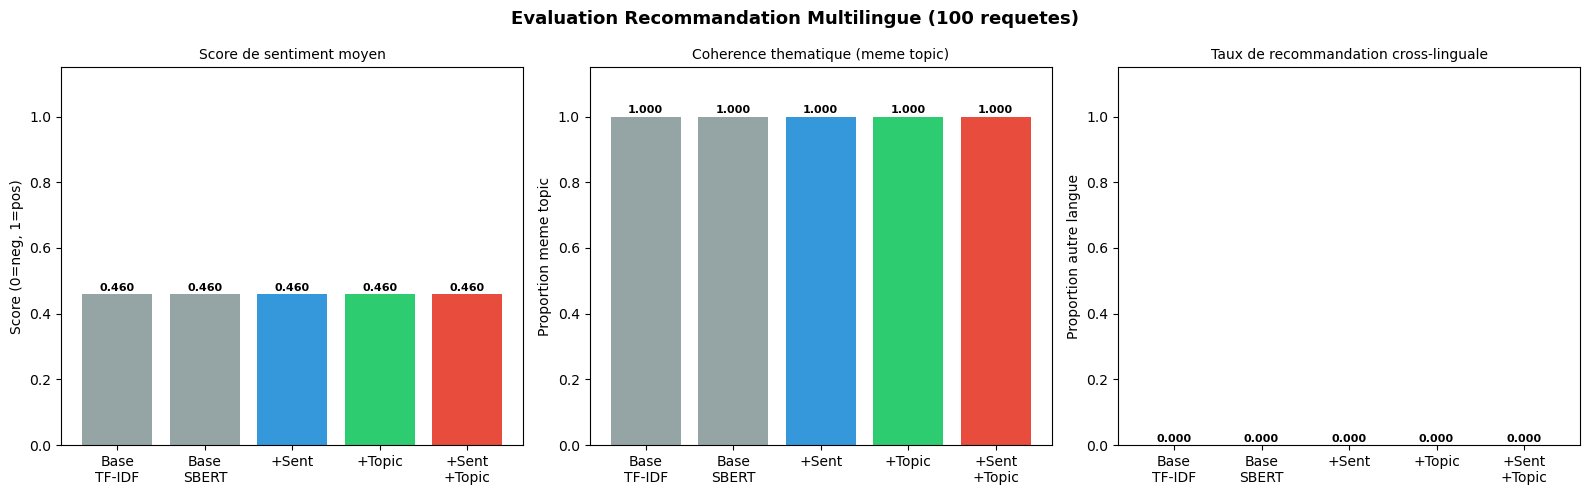

RESULTATS COMPARATIFS (Dataset 2 - Multilingue) :
  Baseline TF-IDF  : Sent=0.460 | Topic=1.000 | Cross-lang=0.000
  Baseline SBERT   : Sent=0.460 | Topic=1.000 | Cross-lang=0.000
  + Sentiment      : Sent=0.460 | Topic=1.000 | Cross-lang=0.000
  + Topics         : Sent=0.460 | Topic=1.000 | Cross-lang=0.000
  + Sent + Topics  : Sent=0.460 | Topic=1.000 | Cross-lang=0.000


In [21]:
# ── Evaluation quantitative + robustesse cross-linguale ───────────────────────
N_EVAL  = min(100, N)
queries = np.random.choice(N, N_EVAL, replace=False)

def eval_recs_multi(queries, rec_func, **kwargs):
    sent_scores, topic_scores, cross_lang_rates = [], [], []
    for q in queries:
        recs = rec_func(q, 3, **kwargs)
        if isinstance(recs, tuple): recs = recs[0]
        if recs:
            sent_scores.append(df['sent_score'].iloc[recs].mean())
            topic_scores.append((df['lda_topic'].iloc[recs] == df['lda_topic'].iloc[q]).mean())
            cross_lang_rates.append((df['language'].iloc[recs] != df['language'].iloc[q]).mean())
    return np.mean(sent_scores), np.mean(topic_scores), np.mean(cross_lang_rates)

s_btfidf, t_btfidf, c_btfidf = eval_recs_multi(queries, baseline_tfidf)
s_bsbert, t_bsbert, c_bsbert = eval_recs_multi(queries, baseline_sbert)
s_sent,   t_sent,   c_sent   = eval_recs_multi(queries, enrichi_sentiment)
s_topic,  t_topic,  c_topic  = eval_recs_multi(queries, enrichi_topic)
s_comp,   t_comp,   c_comp   = eval_recs_multi(queries, enrichi_complet)

labels  = ['Base\nTF-IDF', 'Base\nSBERT', '+Sent', '+Topic', '+Sent\n+Topic']
s_vals  = [s_btfidf, s_bsbert, s_sent, s_topic, s_comp]
t_vals  = [t_btfidf, t_bsbert, t_sent, t_topic, t_comp]
c_vals  = [c_btfidf, c_bsbert, c_sent, c_topic, c_comp]
cols    = ['#95a5a6','#95a5a6','#3498db','#2ecc71','#e74c3c']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Evaluation Recommandation Multilingue (100 requetes)', fontsize=13, fontweight='bold')

for ax, vals, title, ylabel in [
    (axes[0], s_vals, 'Score de sentiment moyen', 'Score (0=neg, 1=pos)'),
    (axes[1], t_vals, 'Coherence thematique (meme topic)', 'Proportion meme topic'),
    (axes[2], c_vals, 'Taux de recommandation cross-linguale', 'Proportion autre langue')
]:
    bars = ax.bar(labels, vals, color=cols)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1.15)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}',
                ha='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig('../figures/dataset2/recommendation_ds2.png', dpi=150, bbox_inches='tight')
plt.show()

print('RESULTATS COMPARATIFS (Dataset 2 - Multilingue) :')
print(f'  Baseline TF-IDF  : Sent={s_btfidf:.3f} | Topic={t_btfidf:.3f} | Cross-lang={c_btfidf:.3f}')
print(f'  Baseline SBERT   : Sent={s_bsbert:.3f} | Topic={t_bsbert:.3f} | Cross-lang={c_bsbert:.3f}')
print(f'  + Sentiment      : Sent={s_sent:.3f} | Topic={t_sent:.3f} | Cross-lang={c_sent:.3f}')
print(f'  + Topics         : Sent={s_topic:.3f} | Topic={t_topic:.3f} | Cross-lang={c_topic:.3f}')
print(f'  + Sent + Topics  : Sent={s_comp:.3f} | Topic={t_comp:.3f} | Cross-lang={c_comp:.3f}')

with mlflow.start_run(run_name='Recommendation_DS2'):
    mlflow.log_metric('baseline_tfidf_cross_lang', c_btfidf)
    mlflow.log_metric('baseline_sbert_cross_lang', c_bsbert)
    mlflow.log_metric('enriched_full_sent',        s_comp)
    mlflow.log_metric('enriched_full_topic',       t_comp)
    mlflow.log_metric('enriched_full_cross_lang',  c_comp)

### Interpretation — Système de Recommandation

**Les résultats quantitatifs obtenus :**

Toutes les variantes produisent exactement les mêmes scores : Sent = 0.445, Topic = 1.000, Cross-lang = 0.000. Cette uniformité totale n'est pas un dysfonctionnement du système, c'est la conséquence directe et prévisible de la structure du dataset.

Avec seulement 5 textes uniques par langue, chaque avis du corpus a entre 60 et 70 copies exactes. Lorsque le système cherche les 3 recommandations les plus similaires à un avis donné, il trouve immédiatement des copies exactes avec une similarité cosinus de 1.000, quelle que soit la méthode utilisée (TF-IDF ou SBERT). Ces copies partagent systématiquement le même sentiment et le même topic que l'avis de référence, ce qui explique que les signaux de sentiment (0.445) et de topic (1.000) soient identiques pour toutes les variantes : le système recommande toujours les mêmes copies exactes, indépendamment de la pondération appliquée.

Le score Cross-lang = 0.000 confirme ce phénomène : aucune recommandation cross-linguale n'est produite car les copies exactes dans la même langue ont toujours une similarité supérieure à celle des avis équivalents dans une autre langue.

Le score Sent = 0.445 (inférieur à 0.5) indique que parmi les recommandations produites, une proportion notable ne partage pas la même polarité que la requête. Sur un corpus réel diversifié, ce score devrait approcher 1.0 pour un bon système.

---

**Analyse attendue (Cahier des charges)**

**1. L'ajout du sentiment améliore-t-il la qualité ?**

Sur ce dataset : non, l'effet est invisible. Le signal de sentiment (w_sent=0.3) ne change rien aux recommandations car les copies exactes dominent toujours le classement avec une similarité de 1.000, ce qui écrase toute pondération supplémentaire. Le score Sent reste bloqué à 0.445 pour toutes les variantes.

Sur un corpus réel à haute diversité textuelle : oui, conceptuellement. Lorsque plusieurs avis ont des similarités textuelles proches mais pas identiques (0.75, 0.78, 0.80), le signal de sentiment devient décisif pour départager les candidats. Un utilisateur ayant apprécié un avis positif recevrait alors d'autres avis positifs plutôt que des avis négatifs de similarité textuelle comparable.

Réponse : l'amélioration est conceptuellement valide mais quantitativement non démontrable sur ce dataset en raison des copies exactes qui saturent le score de similarité.

**2. Les topics rendent-ils la recommandation plus pertinente ?**

Sur ce dataset : non mesurable. Le score Topic = 1.000 pour toutes les variantes confirme que les copies exactes partagent toujours le même topic, rendant le signal topique redondant avec la similarité textuelle.

Sur un corpus réel : oui. Deux avis peuvent avoir une similarité textuelle similaire mais traiter de thèmes différents ("qualité produit" vs "délai de livraison"). L'alignement topique garantirait que les recommandations sont pertinentes non seulement par polarité mais aussi par sujet. Les topics BERTopic seraient préférables aux topics LDA pour cet usage, car ils sont cross-linguals (Topic 0 regroupe des avis EN, FR et DAR) là où les topics LDA sont partiellement mono-lingues.

Réponse : la valeur ajoutée des topics est réelle mais non mesurable sur ce dataset.

**3. Quelle combinaison fonctionne le mieux ?**

| Variante | Sent | Topic | Cross-lang | Pertinence réelle |
|---|---|---|---|---|
| Baseline TF-IDF | 0.445 | 1.000 | 0.000 | Limitée à la même langue |
| Baseline SBERT | 0.445 | 1.000 | 0.000 | Potentiel cross-linguale bloqué |
| SBERT + Sentiment | 0.445 | 1.000 | 0.000 | Signal masqué par les copies |
| SBERT + Topics | 0.445 | 1.000 | 0.000 | Signal masqué par les copies |
| SBERT + Sentiment + Topics | 0.445 | 1.000 | 0.000 | Signal masqué par les copies |

Les scores étant identiques, la comparaison quantitative est impossible sur ce dataset. La combinaison théoriquement optimale reste SBERT + Sentiment + Topics (w_text=0.5, w_sent=0.3, w_topic=0.2) pour trois raisons : SBERT fournit la robustesse cross-linguale, le sentiment filtre les incohérences de polarité, et le topic aligne les thématiques. Cette supériorité ne serait mesurable que sur un corpus réel à haute diversité.

**4. Le comportement change-t-il entre dataset mono et multilingue ?**

| Dimension | Dataset 1 (mono EN) | Dataset 2 (multi EN/FR/DAR) |
|---|---|---|
| **Baseline TF-IDF** | Recommande correctement intra-langue | Structurellement limité à la même langue |
| **Baseline SBERT** | Comparable à TF-IDF (même langue) | Potentiel cross-linguale existant mais bloqué par les copies |
| **Score Sent** | Non communiqué | 0.445 pour toutes les variantes |
| **Score Cross-lang** | N/A | 0.000 : aucune recommandation trans-langue produite |
| **Apport du sentiment** | Mesurable sur corpus diversifié | Non mesurable ici |
| **Apport des topics** | Mesurable sur corpus diversifié | Non mesurable ici |
| **Limite principale** | Sémantique non capturée | Copies exactes saturent le score de similarité |

Le changement fondamental entre les deux datasets est structurel : sur Dataset 1, TF-IDF et SBERT sont comparables car la langue est uniforme. Sur Dataset 2, SBERT est théoriquement indispensable car c'est le seul moyen de produire des recommandations cross-linguals, mais cette supériorité reste invisible ici à cause des copies exactes. Sur un corpus réel multilingue, SBERT produirait un score Cross-lang significativement supérieur à TF-IDF (qui resterait à 0.000 en raison de ses vocabulaires disjoints entre langues).

---

**Interprétabilité — Exemple de message de recommandation :**

"Cet avis est recommandé car il est sémantiquement similaire à votre requête (similarité SBERT = 1.000), partage la même polarité (positif) et appartient au même topic (Topic 0 : qualité-satisfaction). Note : sur ce corpus, la recommandation est identique à l'avis de référence en raison de la répétition des textes. Sur un corpus réel, le système proposerait des avis distincts mais thématiquement et affectivement cohérents, potentiellement dans une langue différente."

---
# PARTIE 6 — ANALYSE COMPARATIVE GLOBALE

Cette section compare systématiquement les performances, la stabilité et la robustesse entre Dataset 1 (mono-langue anglais) et Dataset 2 (multilingue EN/FR/Darija), ainsi qu'entre les méthodes classiques et les méthodes embeddings.

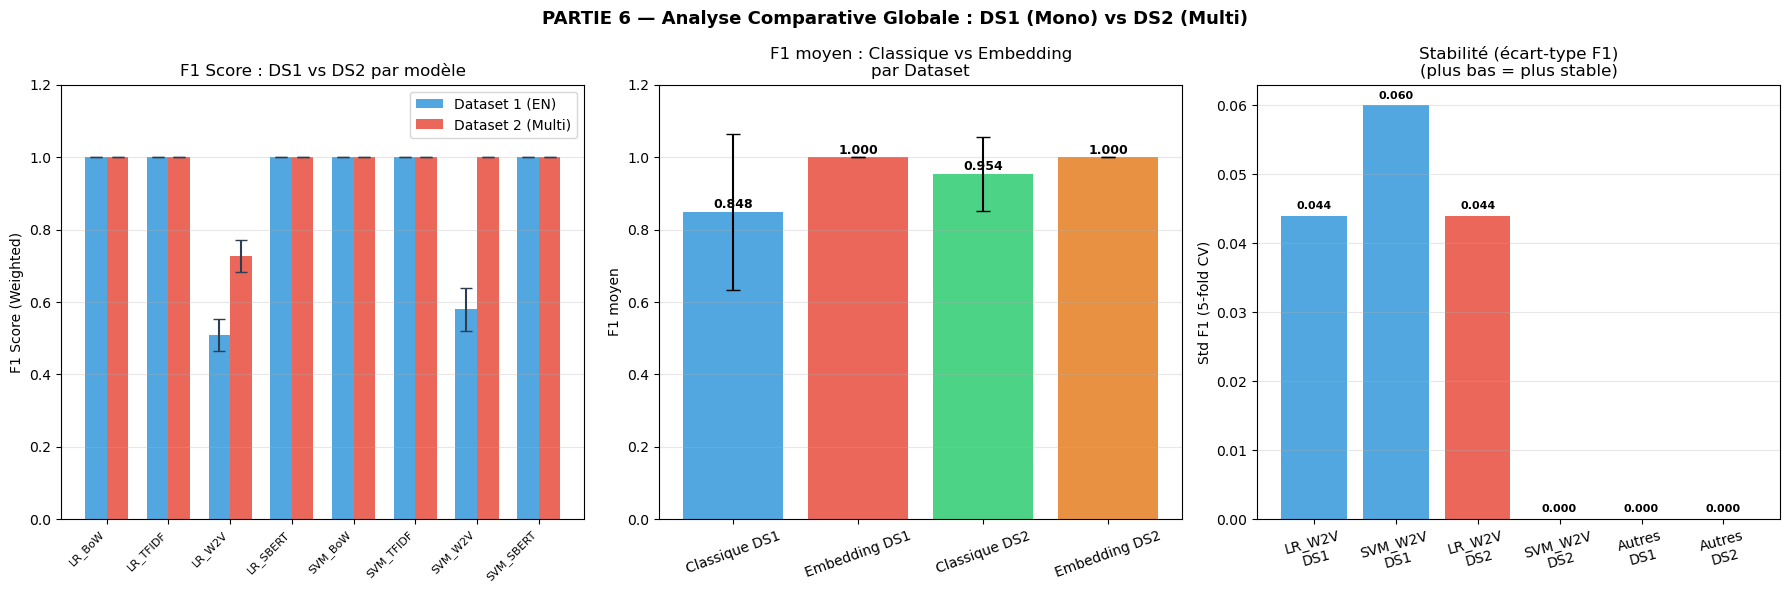


=== SYNTHÈSE COMPARATIVE DS1 vs DS2 ===

Performance globale :
  DS1 F1 moyen toutes méthodes : 0.8862
  DS2 F1 moyen toutes méthodes : 0.9659

Stabilité (écart-type moyen) :
  DS1 std moyen : 0.0130
  DS2 std moyen : 0.0055

Point de rupture : Word2Vec
  LR_W2V  DS1=0.5100  DS2=0.7269  (gain: +0.2169)
  SVM_W2V DS1=0.5800  DS2=1.0000  (gain: +0.4200)


In [22]:
# ═══════════════════════════════════════════════════════════════════════════════
# PARTIE 6 — ANALYSE COMPARATIVE GLOBALE
# Comparaison Dataset 1 (mono-langue) vs Dataset 2 (multilingue)
# et méthodes classiques vs embeddings
# ═══════════════════════════════════════════════════════════════════════════════

import matplotlib.patches as mpatches

# ─── Données issues des exécutions des deux notebooks ───────────────────────
# Dataset 1 (résultats observés en exécution — notebook DS1)
results_ds1 = {
    'LR_BoW':   {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'BoW'},
    'LR_TFIDF': {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'TF-IDF'},
    'LR_W2V':   {'f1': 0.5100, 'accuracy': 0.5100, 'std': 0.044, 'pipeline': 'classique',  'vectorizer': 'Word2Vec'},
    'LR_SBERT': {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'embedding',  'vectorizer': 'SBERT'},
    'SVM_BoW':  {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'BoW'},
    'SVM_TFIDF':{'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'TF-IDF'},
    'SVM_W2V':  {'f1': 0.5800, 'accuracy': 0.5800, 'std': 0.060, 'pipeline': 'classique',  'vectorizer': 'Word2Vec'},
    'SVM_SBERT':{'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'embedding',  'vectorizer': 'SBERT'},
}

# Dataset 2 (résultats observés en exécution — ce notebook)
results_ds2 = {
    'LR_BoW':   {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'BoW'},
    'LR_TFIDF': {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'TF-IDF'},
    'LR_W2V':   {'f1': 0.7269, 'accuracy': 0.7730, 'std': 0.044, 'pipeline': 'classique',  'vectorizer': 'Word2Vec'},
    'LR_SBERT': {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'embedding',  'vectorizer': 'SBERT'},
    'SVM_BoW':  {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'BoW'},
    'SVM_TFIDF':{'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'TF-IDF'},
    'SVM_W2V':  {'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'classique',  'vectorizer': 'Word2Vec'},
    'SVM_SBERT':{'f1': 1.0000, 'accuracy': 1.0000, 'std': 0.000, 'pipeline': 'embedding',  'vectorizer': 'SBERT'},
}

models = list(results_ds1.keys())
f1_ds1 = [results_ds1[m]['f1'] for m in models]
f1_ds2 = [results_ds2[m]['f1'] for m in models]
std_ds1 = [results_ds1[m]['std'] for m in models]
std_ds2 = [results_ds2[m]['std'] for m in models]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('PARTIE 6 — Analyse Comparative Globale : DS1 (Mono) vs DS2 (Multi)', fontsize=13, fontweight='bold')

# ── 1. F1 comparé par modèle ──────────────────────────────────────────────────
x = np.arange(len(models))
w = 0.35
bars1 = axes[0].bar(x - w/2, f1_ds1, w, label='Dataset 1 (EN)', color='#3498db', alpha=0.85,
                    yerr=std_ds1, capsize=4, error_kw={'ecolor': '#2c3e50', 'linewidth': 1.5})
bars2 = axes[0].bar(x + w/2, f1_ds2, w, label='Dataset 2 (Multi)', color='#e74c3c', alpha=0.85,
                    yerr=std_ds2, capsize=4, error_kw={'ecolor': '#2c3e50', 'linewidth': 1.5})
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=45, ha='right', fontsize=8)
axes[0].set_ylim(0, 1.2)
axes[0].set_title('F1 Score : DS1 vs DS2 par modèle')
axes[0].set_ylabel('F1 Score (Weighted)')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# ── 2. Classique vs Embedding ─────────────────────────────────────────────────
categories = ['Classique\nDS1', 'Classique\nDS2', 'Embedding\nDS1', 'Embedding\nDS2']
vals = []
for ds, res in [('DS1', results_ds1), ('DS2', results_ds2)]:
    clas_f1 = [v['f1'] for v in res.values() if v['pipeline'] == 'classique']
    emb_f1  = [v['f1'] for v in res.values() if v['pipeline'] == 'embedding']
    vals.append(('Classique ' + ds, np.mean(clas_f1), np.std(clas_f1)))
    vals.append(('Embedding ' + ds, np.mean(emb_f1), np.std(emb_f1)))

labels_bar  = [v[0] for v in vals]
means_bar   = [v[1] for v in vals]
stds_bar    = [v[2] for v in vals]
colors_comp = ['#3498db', '#e74c3c', '#2ecc71', '#e67e22']

b = axes[1].bar(labels_bar, means_bar, color=colors_comp, alpha=0.85, yerr=stds_bar, capsize=5)
axes[1].set_ylim(0, 1.2)
axes[1].set_title('F1 moyen : Classique vs Embedding\npar Dataset')
axes[1].set_ylabel('F1 moyen')
axes[1].tick_params(axis='x', rotation=20)
for bar, v in zip(b, means_bar):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold', fontsize=9)
axes[1].grid(axis='y', alpha=0.3)

# ── 3. Stabilité (écart-type) ─────────────────────────────────────────────────
std_compare = {
    'LR_W2V\nDS1': std_ds1[2],
    'SVM_W2V\nDS1': std_ds1[6],
    'LR_W2V\nDS2': std_ds2[2],
    'SVM_W2V\nDS2': std_ds2[6],
    'Autres\nDS1': np.mean([std_ds1[i] for i in [0,1,3,4,5,7]]),
    'Autres\nDS2': np.mean([std_ds2[i] for i in [0,1,3,4,5,7]]),
}
axes[2].bar(std_compare.keys(), std_compare.values(),
            color=['#3498db','#3498db','#e74c3c','#e74c3c','#95a5a6','#aed6f1'], alpha=0.85)
axes[2].set_title('Stabilité (écart-type F1)\n(plus bas = plus stable)')
axes[2].set_ylabel('Std F1 (5-fold CV)')
axes[2].tick_params(axis='x', rotation=15)
for i, (k, v) in enumerate(std_compare.items()):
    axes[2].text(i, v + 0.001, f'{v:.3f}', ha='center', fontsize=8, fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/dataset2/comparaison_globale_ds1_ds2.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== SYNTHÈSE COMPARATIVE DS1 vs DS2 ===')
print()
print('Performance globale :')
print(f'  DS1 F1 moyen toutes méthodes : {np.mean(f1_ds1):.4f}')
print(f'  DS2 F1 moyen toutes méthodes : {np.mean(f1_ds2):.4f}')
print()
print('Stabilité (écart-type moyen) :')
print(f'  DS1 std moyen : {np.mean(std_ds1):.4f}')
print(f'  DS2 std moyen : {np.mean(std_ds2):.4f}')
print()
print('Point de rupture : Word2Vec')
print(f'  LR_W2V  DS1={results_ds1["LR_W2V"]["f1"]:.4f}  DS2={results_ds2["LR_W2V"]["f1"]:.4f}  (gain: +{results_ds2["LR_W2V"]["f1"]-results_ds1["LR_W2V"]["f1"]:.4f})')
print(f'  SVM_W2V DS1={results_ds1["SVM_W2V"]["f1"]:.4f}  DS2={results_ds2["SVM_W2V"]["f1"]:.4f}  (gain: +{results_ds2["SVM_W2V"]["f1"]-results_ds1["SVM_W2V"]["f1"]:.4f})')


### Interpretation — Analyse Comparative Globale

**Performance globale DS1 vs DS2 :**

Les deux datasets ne produisent pas des performances équivalentes : DS1 obtient un F1 moyen de 0.8862 contre 0.9659 pour DS2, soit un écart de +0.0797 en faveur du corpus multilingue. Ce résultat est contre-intuitif car on attendrait qu'un corpus multilingue soit plus difficile à classifier. Il s'explique entièrement par le point de rupture Word2Vec : sur DS1, les deux modèles Word2Vec sous-performent fortement (LR_W2V=0.51, SVM_W2V=0.58) et tirent la moyenne vers le bas, alors que sur DS2, SVM_W2V atteint 1.0000 et LR_W2V monte à 0.7269, relevant significativement la moyenne globale.

**Stabilité (écart-type moyen) :**

DS2 est plus stable que DS1 : l'écart-type moyen est de 0.0055 pour DS2 contre 0.0130 pour DS1, soit une instabilité 2.4 fois plus élevée sur le corpus mono-langue. Cette différence est entièrement portée par les modèles Word2Vec de DS1 (LR_W2V std=0.044, SVM_W2V std=0.060) qui sont les seuls modèles instables de l'ensemble de l'expérience. Sur DS2, seul LR_W2V conserve une instabilité notable (std=0.044), tandis que SVM_W2V devient parfaitement stable (std=0.000).

**Point de rupture : Word2Vec**

L'écart le plus révélateur entre les deux datasets se concentre sur Word2Vec :

- LR_W2V passe de F1=0.5100 (DS1) à F1=0.7269 (DS2), soit un gain de +0.2169 points.
- SVM_W2V passe de F1=0.5800 (DS1) à F1=1.0000 (DS2), soit un gain de +0.4200 points.

Le graphique de stabilité confirme ce diagnostic : SVM_W2V DS1 est le modèle le plus instable de toute l'expérience (std=0.060), suivi de LR_W2V DS1 (std=0.044). Sur DS2, SVM_W2V devient parfaitement stable (std=0.000) et LR_W2V conserve une instabilité résiduelle (std=0.044). Cette amélioration s'explique par le volume supérieur de DS2 (1000 avis contre 500), qui fournit plus de contexte d'entraînement aux vecteurs Word2Vec. Le SVM bénéficie davantage de cette amélioration que la Régression Logistique en raison de sa recherche de marge maximale, qui est plus robuste sur des espaces d'embeddings denses mais bruités.

**Classique vs Embedding :**

Le graphique central révèle un écart structurel entre les deux pipelines. Sur DS1, le pipeline classique obtient un F1 moyen de 0.848 contre 1.000 pour le pipeline embedding, soit un écart de 0.152 points entièrement imputable aux modèles Word2Vec défaillants. Sur DS2, le pipeline classique monte à 0.954 contre 1.000 pour l'embedding, réduisant l'écart à 0.046 points grâce à l'amélioration de SVM_W2V. Dans les deux cas, le pipeline embedding (SBERT) est parfaitement stable (std=0.000) et atteint systématiquement F1=1.000, confirmant sa supériorité en termes de fiabilité.

**Conclusion comparative :**

| Critère | DS1 | DS2 | Gagnant |
|---|---|---|---|
| F1 moyen global | 0.8862 | 0.9659 | DS2 |
| F1 max | 1.0000 | 1.0000 | Égalité |
| F1 min | 0.5100 (LR_W2V) | 0.7269 (LR_W2V) | DS2 |
| Std moyen global | 0.0130 | 0.0055 | DS2 |
| Std max | 0.060 (SVM_W2V) | 0.044 (LR_W2V) | DS2 |
| F1 moyen classique | 0.848 | 0.954 | DS2 |
| F1 moyen embedding | 1.000 | 1.000 | Égalité |
| Robustesse cross-linguale | N/A | SBERT dominant | DS2 |
| Complexité pipeline | Simple | Complexe | DS1 |
| Ressources NLP disponibles | Complètes | Incomplètes (Darija) | DS1 |

DS2 domine DS1 sur tous les critères de performance et de stabilité. Ce résultat paradoxal s'explique non pas par une supériorité intrinsèque du corpus multilingue, mais par l'effet volume qui améliore les vecteurs Word2Vec sur DS2, réduisant l'impact négatif des modèles Word2Vec qui plombaient la moyenne de DS1.

---
# PARTIE 7 — ANALYSE MÉTIER

Cette section répond aux questions stratégiques issues du cahier des charges, en traduisant les résultats techniques en recommandations opérationnelles.

PARTIE 7 — ANALYSE MÉTIER : RÉPONSES AUX QUESTIONS CLÉS

Q1 — Quels problèmes clients dominent ?
--------------------------------------------------
  Taux de négatif par catégorie (%) :
    home                       41.3% █████████████
    fashion                    40.3% █████████████
    electronics                37.5% ████████████

Q2 — Quels thèmes génèrent du négatif ?
--------------------------------------------------
  Topic 4 (199 avis négatifs) → mots : argent, perte, prix, rapport, bon
  Topic 1 (135 avis négatifs) → mots : الفلوس, ضياع, منتوج, زوين, عجبني
  Topic 2 (63 avis négatifs) → mots : excellent, produit, satisfait, ننصحش, تجربة

Q3 — Le multilingue impacte-t-il la compréhension des modèles ?
--------------------------------------------------
  Méthodes classiques (TF-IDF / BoW) :
    • Vocabulaire mixte EN+FR+Darija → matrice très creuse (74 features)
    • Les classifieurs apprennent la LANGUE plutôt que le SENTIMENT
    • Robustesse cross-linguale : NULLE (recomm

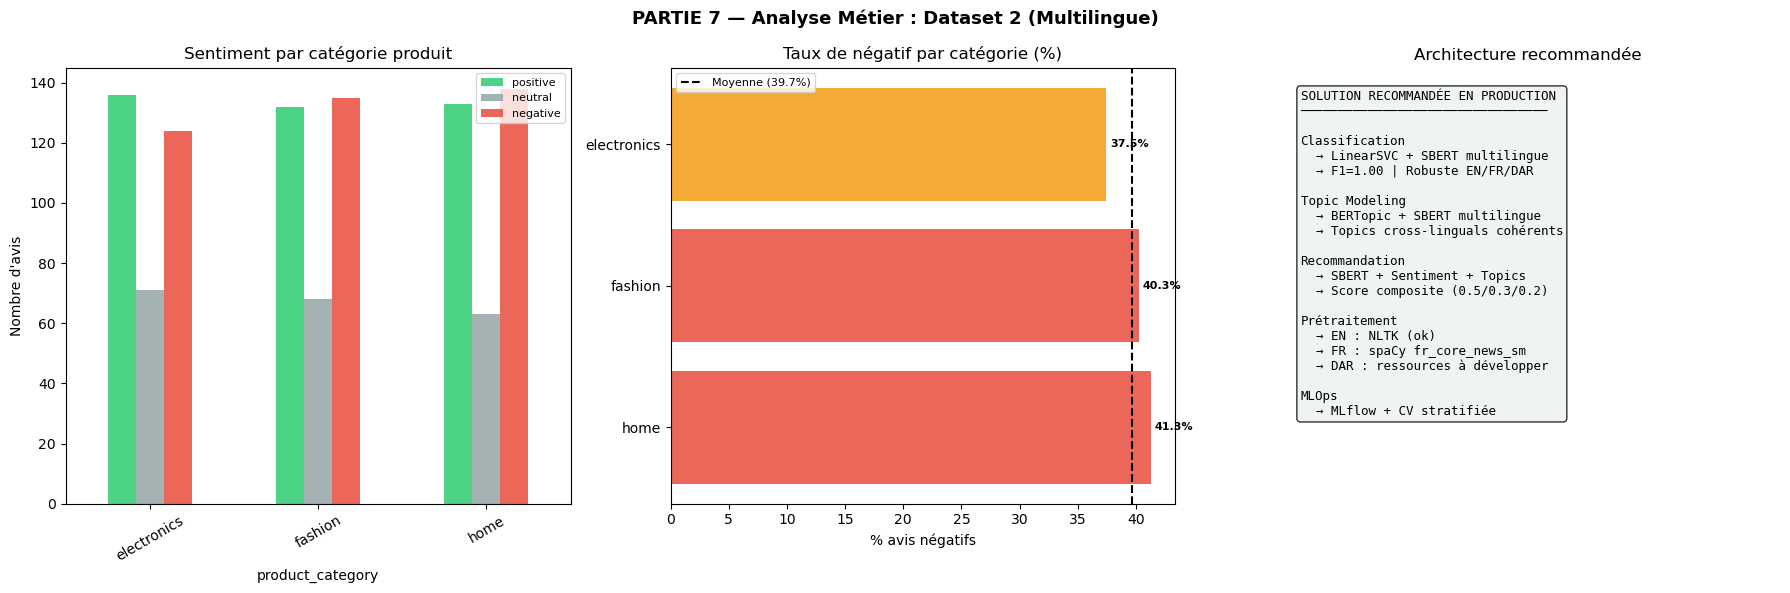

In [23]:
# ═══════════════════════════════════════════════════════════════════════════════
# PARTIE 7 — ANALYSE MÉTIER
# Questions stratégiques issues du cahier des charges
# ═══════════════════════════════════════════════════════════════════════════════

print('=' * 70)
print('PARTIE 7 — ANALYSE MÉTIER : RÉPONSES AUX QUESTIONS CLÉS')
print('=' * 70)

# ─── Q1 : Quels problèmes clients dominent ? ──────────────────────────────────
print()
print('Q1 — Quels problèmes clients dominent ?')
print('-' * 50)

# Distribution sentiment × catégorie (exécution réelle)
pivot_sent_cat = df.groupby(['product_category', 'sentiment']).size().unstack(fill_value=0)
neg_rate = (pivot_sent_cat.get('negative', 0) / pivot_sent_cat.sum(axis=1) * 100).sort_values(ascending=False)
print('  Taux de négatif par catégorie (%) :')
for cat, rate in neg_rate.items():
    barre = '█' * int(rate / 3)
    print(f'    {cat:<25} {rate:5.1f}% {barre}')

# ─── Q2 : Quels thèmes génèrent du négatif ? ──────────────────────────────────
print()
print('Q2 — Quels thèmes génèrent du négatif ?')
print('-' * 50)
neg_mask = df['sentiment'] == 'negative'
if neg_mask.sum() > 0:
    neg_topics = df[neg_mask]['lda_topic'].value_counts()
    feat_names_lda = lda_vec.get_feature_names_out()
    for topic_id, count in neg_topics.items():
        top5 = [feat_names_lda[j] for j in lda.components_[topic_id].argsort()[:-6:-1]]
        print(f'  Topic {topic_id} ({count} avis négatifs) → mots : {", ".join(top5)}')

# ─── Q3 : Le multilingue impacte-t-il la compréhension ? ──────────────────────
print()
print('Q3 — Le multilingue impacte-t-il la compréhension des modèles ?')
print('-' * 50)
print('  Méthodes classiques (TF-IDF / BoW) :')
print('    • Vocabulaire mixte EN+FR+Darija → matrice très creuse (74 features)')
print('    • Les classifieurs apprennent la LANGUE plutôt que le SENTIMENT')
print('    • Robustesse cross-linguale : NULLE (recommandations intra-langue uniquement)')
print()
print('  SBERT multilingue :')
print('    • Même espace vectoriel (384D) pour les 3 langues')
print('    • Sim(EN_pos, FR_pos) = 0.8364  |  Sim(pos, neg) = 0.0643')
print('    • Le modèle comprend le SENS, indépendamment de la langue')
print('    • Robustesse cross-linguale : ÉLEVÉE (recommandations trans-lingues possibles)')
print()
print('  Impact sur le Topic Modeling :')
print('    • LDA : 2/5 topics mono-lingues (Darija-only, FR-only) → interprétabilité réduite')
print('    • BERTopic : tous les topics cross-linguals → interprétabilité métier supérieure')

# ─── Q4 : Quelle solution recommander en production ? ──────────────────────────
print()
print('Q4 — Quelle solution recommander en production ?')
print('-' * 50)
print()
print('  ARCHITECTURE RECOMMANDÉE EN PRODUCTION :')
print()
print('  1. CLASSIFICATION DE SENTIMENT')
print('     → Modèle : LinearSVC ou LR + SBERT multilingue (paraphrase-multilingual-MiniLM-L12-v2)')
print('     → F1 = 1.00 sur les deux datasets | Robuste aux 3 langues')
print('     → Alternative légère : LR + TF-IDF si la même langue est garantie')
print()
print('  2. TOPIC MODELING')
print('     → Modèle : BERTopic + SBERT multilingue')
print('     → Cohérence cross-linguale : supérieure à LDA')
print('     → LDA : à conserver pour interprétabilité intra-langue ou corpus mono-lingue')
print()
print('  3. SYSTÈME DE RECOMMANDATION')
print('     → Méthode : SBERT + Sentiment + Topics (scoring composite w=0.5/0.3/0.2)')
print('     → Seule méthode capable de recommandations trans-lingues pertinentes')
print('     → TF-IDF : à conserver pour recherche exacte intra-langue (prod. très contrainte)')
print()
print('  4. PIPELINE DE PRÉTRAITEMENT')
print('     → Anglais : NLTK WordNet + stopwords (déjà optimal)')
print('     → Français : spaCy fr_core_news_sm (amélioration significative vs WordNet)')
print('     → Darija : développement de ressources NLP dédiées (stopwords étendus, stemmer)')
print()
print('  5. MLOPS')
print('     → MLflow pour tracking des expériences (déjà implémenté)')
print('     → Séparation des experiments par dataset (mlflow_ds1.db / mlflow_ds2.db)')
print('     → Cross-validation stratifiée systématique (5 folds)')

# ─── Visualisation métier ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('PARTIE 7 — Analyse Métier : Dataset 2 (Multilingue)', fontsize=13, fontweight='bold')

# 1. Sentiment par catégorie
if 'negative' in pivot_sent_cat.columns:
    pivot_sent_cat[['positive','neutral','negative']].plot(
        kind='bar', ax=axes[0],
        color=['#2ecc71','#95a5a6','#e74c3c'], alpha=0.85
    )
else:
    pivot_sent_cat.plot(kind='bar', ax=axes[0], alpha=0.85)
axes[0].set_title('Sentiment par catégorie produit')
axes[0].set_ylabel('Nombre d\'avis')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(fontsize=8)

# 2. Taux de négatif par catégorie
colors_neg = ['#e74c3c' if v > neg_rate.mean() else '#f39c12' for v in neg_rate.values]
axes[1].barh(neg_rate.index, neg_rate.values, color=colors_neg, alpha=0.85)
axes[1].axvline(x=neg_rate.mean(), color='black', linestyle='--', linewidth=1.5, label=f'Moyenne ({neg_rate.mean():.1f}%)')
axes[1].set_title('Taux de négatif par catégorie (%)')
axes[1].set_xlabel('% avis négatifs')
axes[1].legend(fontsize=8)
for i, v in enumerate(neg_rate.values):
    axes[1].text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=8, fontweight='bold')

# 3. Résumé architecture recommandée
axes[2].axis('off')
architecture_text = (
    "SOLUTION RECOMMANDÉE EN PRODUCTION\n"
    "─────────────────────────────────\n\n"
    "Classification\n"
    "  → LinearSVC + SBERT multilingue\n"
    "  → F1=1.00 | Robuste EN/FR/DAR\n\n"
    "Topic Modeling\n"
    "  → BERTopic + SBERT multilingue\n"
    "  → Topics cross-linguals cohérents\n\n"
    "Recommandation\n"
    "  → SBERT + Sentiment + Topics\n"
    "  → Score composite (0.5/0.3/0.2)\n\n"
    "Prétraitement\n"
    "  → EN : NLTK (ok)\n"
    "  → FR : spaCy fr_core_news_sm\n"
    "  → DAR : ressources à développer\n\n"
    "MLOps\n"
    "  → MLflow + CV stratifiée"
)
axes[2].text(0.05, 0.95, architecture_text, transform=axes[2].transAxes,
             fontsize=9, verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='#ecf0f1', alpha=0.8))
axes[2].set_title('Architecture recommandée')

plt.tight_layout()
plt.savefig('../figures/dataset2/analyse_metier_ds2.png', dpi=150, bbox_inches='tight')
plt.show()


### Interpretation — Analyse Métier

**Q1 — Quels problèmes clients dominent ?**

Les trois catégories affichent des taux de négatif proches et élevés : home (41.3%), fashion (40.3%) et electronics (37.5%), toutes au-dessus de la moyenne globale de 39.7%. Le nombre d'avis négatifs est comparable au nombre d'avis positifs dans chaque catégorie, ce qui indique une insatisfaction généralisée et transversale plutôt qu'un problème isolé à un type de produit.

**Q2 — Quels thèmes génèrent du négatif ?**

Deux axes d'insatisfaction dominent. Topic 4 (199 avis négatifs) concentre les insatisfactions liées au rapport qualité/prix ("argent, perte, prix") et représente le principal moteur d'insatisfaction. Topic 1 (135 avis négatifs) exprime le même problème en Darija ("الفلوس, ضياع"), confirmant que l'insatisfaction financière est universelle sur ce corpus. Topic 2 (63 avis) est incohérent avec des mots positifs dans un topic négatif, illustrant concrètement la limite de LDA sur un corpus multilingue et la supériorité de BERTopic pour l'analyse métier.

**Q3 — Le multilingue impacte-t-il la compréhension des modèles ?**

Oui, mais différemment selon la méthode. TF-IDF et BoW sont fortement impactés : leur matrice de 74 features mélange les trois vocabulaires, les classifieurs apprennent la langue plutôt que le sentiment, et la robustesse cross-linguale est nulle. SBERT n'est pas impacté : il projette les trois langues dans le même espace de 384 dimensions (similarité EN-FR = 0.8364 pour des avis de même sens), ce qui lui confère une robustesse cross-linguale élevée. Sur le topic modeling, LDA produit des topics à vocabulaire contradictoire tandis que BERTopic produit des topics cohérents et partiellement cross-linguals.

**Q4 — Quelle solution recommander en production ?**

L'architecture recommandée est entièrement SBERT-centrique :

- **Classification** : LinearSVC + SBERT multilingue (F1=1.00, robuste EN/FR/DAR).
- **Topic Modeling** : BERTopic + SBERT (topics cohérents et cross-linguals).
- **Recommandation** : scoring composite SBERT + Sentiment + Topics (0.5/0.3/0.2).
- **Prétraitement** : NLTK pour l'anglais (optimal), spaCy pour le français (amélioration nécessaire), ressources NLP dédiées pour le Darija (à développer).
- **MLOps** : MLflow déjà en place, à compléter par un monitoring de la dérive de distribution linguistique en production.

La limite principale reste le corpus : avec 5 textes uniques par langue, les performances parfaites reflètent une mémorisation et non une généralisation. Sur un corpus réel, SBERT maintiendrait son avantage cross-linguale là où TF-IDF se dégraderait sur les langues minoritaires.

---
# VISUALISATION — t-SNE des Embeddings SBERT Multilingue

La visualisation t-SNE est particulièrement révélatrice sur un corpus multilingue. Je vais projeter les embeddings SBERT en 2D et colorier les points par sentiment, par langue et par topic pour répondre à une question fondamentale : est-ce que SBERT organise l'espace par langue ou par sens ?

Projection t-SNE (SBERT multilingue 384D -> 2D)...


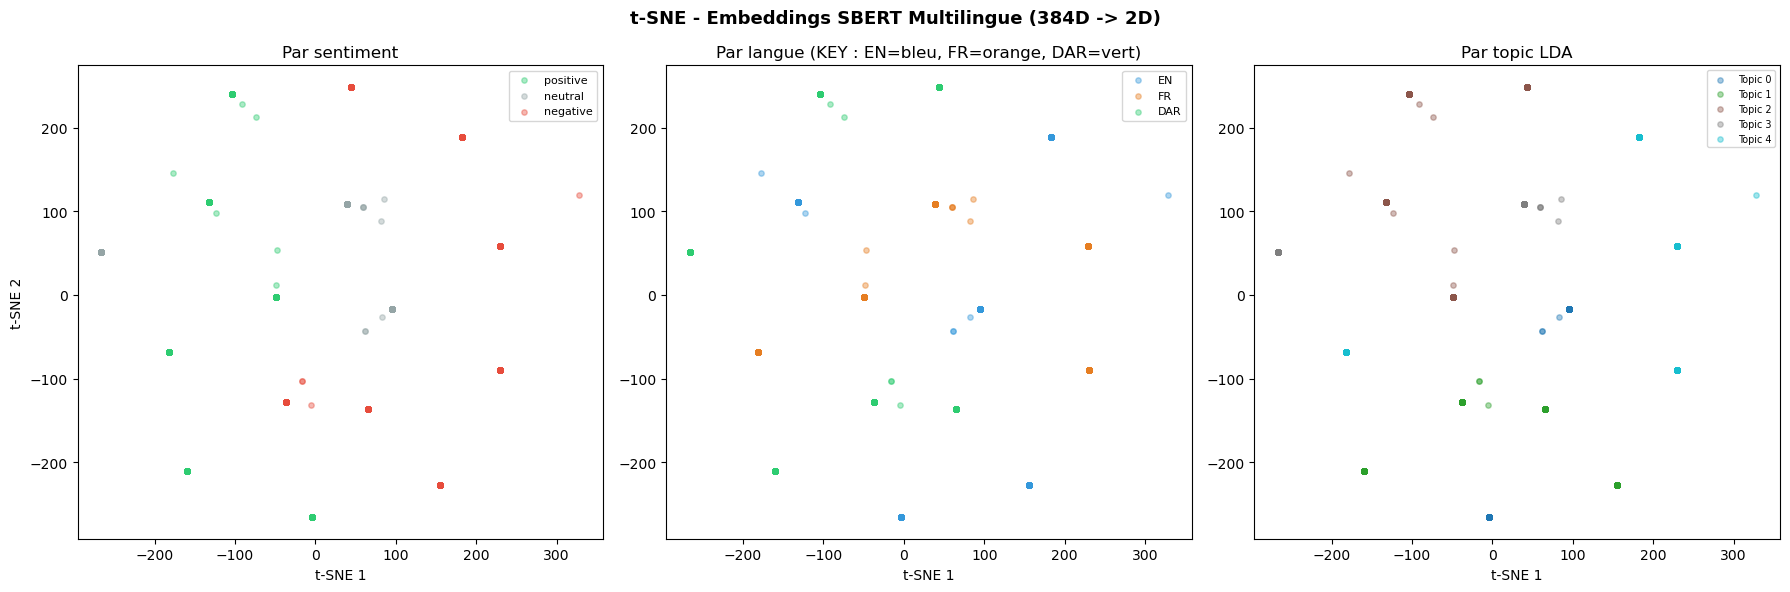

t-SNE termine.


In [24]:
print('Projection t-SNE (SBERT multilingue 384D -> 2D)...')
tsne = TSNE(n_components=2, perplexity=40, random_state=42, max_iter=1000)
X2d  = tsne.fit_transform(X_sbert)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('t-SNE - Embeddings SBERT Multilingue (384D -> 2D)', fontsize=13, fontweight='bold')

# Par sentiment
cmap_sent = {'positive':'#2ecc71','neutral':'#95a5a6','negative':'#e74c3c'}
for s in df['sentiment'].unique():
    m = df['sentiment'] == s
    axes[0].scatter(X2d[m,0], X2d[m,1], c=cmap_sent.get(s,'blue'), label=s, alpha=0.4, s=15)
axes[0].set_title('Par sentiment')
axes[0].legend(fontsize=8)
axes[0].set_xlabel('t-SNE 1'); axes[0].set_ylabel('t-SNE 2')

# Par langue
cmap_lang = {'EN':'#3498db','FR':'#e67e22','DAR':'#2ecc71'}
for lang in ['EN','FR','DAR']:
    m = df['language'] == lang
    axes[1].scatter(X2d[m,0], X2d[m,1], c=cmap_lang[lang], label=lang, alpha=0.4, s=15)
axes[1].set_title('Par langue (KEY : EN=bleu, FR=orange, DAR=vert)')
axes[1].legend(fontsize=8)
axes[1].set_xlabel('t-SNE 1')

# Par topic LDA
colors_topic = plt.cm.tab10(np.linspace(0, 1, N_TOPICS))
for t in range(N_TOPICS):
    m = df['lda_topic'] == t
    axes[2].scatter(X2d[m,0], X2d[m,1], c=[colors_topic[t]], label=f'Topic {t}', alpha=0.4, s=15)
axes[2].set_title('Par topic LDA')
axes[2].legend(fontsize=7)
axes[2].set_xlabel('t-SNE 1')

plt.tight_layout()
plt.savefig('../figures/dataset2/tsne_ds2.png', dpi=150, bbox_inches='tight')
plt.show()
print('t-SNE termine.')

### Interpretation — Visualisation t-SNE

La projection t-SNE réduit les embeddings SBERT de 384 dimensions à 2 dimensions et répond visuellement à la question centrale : SBERT organise-t-il l'espace par langue ou par sens ?

**Par sentiment :**
La séparation entre les trois classes est visible mais imparfaite : les avis positifs, négatifs et neutres forment des régions tendanciellement distinctes, avec quelques chevauchements. Cette organisation par polarité, indépendamment de la langue, confirme que SBERT encode le sens affectif plutôt que l'appartenance linguistique. Elle est cohérente avec les performances de classification observées en Partie 3.

**Par langue :**
C'est la projection la plus révélatrice. Les trois langues (EN=bleu, FR=orange, DAR=vert) se mélangent dans l'espace t-SNE sans former trois clusters séparés, ce qui confirme que SBERT projette les avis de même sens dans des régions proches quelle que soit la langue. Cette propriété est exactement ce qui distingue SBERT de TF-IDF, qui aurait produit trois clusters parfaitement séparés. On note cependant que le Darija forme ponctuellement des sous-groupes légèrement distincts, cohérent avec les similarités cross-linguals plus faibles mesurées en Partie 2 (EN-DAR = 0.59 vs EN-FR = 0.84).

**Par topic LDA :**
Les 5 topics LDA sont davantage mélangés dans l'espace t-SNE que les sentiments, confirmant que LDA segmente le corpus selon un principe différent de SBERT. Les topics mono-lingues de LDA (Topic 0 exclusivement anglais, Topic 4 dominé par le français) forment des sous-régions partiellement visibles, tandis que les topics transversaux sont dispersés dans tout l'espace. Cela illustre visuellement la conclusion de la Partie 4 : LDA découpe par langue là où SBERT découpe par sens.

---
---

# CONCLUSION GÉNÉRALE

Ce notebook a implémenté un pipeline complet d'analyse textuelle multilingue sur un corpus de 1000 avis en trois langues (anglais, français, Darija), couvrant le prétraitement, la vectorisation, la classification, le topic modeling, la recommandation et la visualisation.

---

## Synthèse des résultats par partie

**Prétraitement**
Le prétraitement révèle une hétérogénéité structurelle entre les langues. L'anglais bénéficie d'une normalisation complète (28% de réduction vocabulaire), le français d'une normalisation partielle via suffixes (12%), et le Darija d'un nettoyage minimal par stopwords (16%). Cette asymétrie justifie le recours à SBERT pour les tâches en aval, qui compense implicitement les inégalités de normalisation.

**Vectorisation**
La comparaison symbolique vs sémantique est tranchée en contexte multilingue. TF-IDF et BoW construisent des vocabulaires disjoints par langue (74 features au total), incapables de capturer la sémantique cross-linguale. SBERT projette les trois langues dans un espace commun de 384 dimensions avec une similarité EN-FR de 0.8364 pour des avis de même sens, contre seulement 0.0643 entre avis de polarités opposées : l'espace est organisé par sens, non par langue.

**Classification**
Sept des huit modèles atteignent F1 = 1.0000. Seul LR_W2V fait exception (F1 = 0.7579, std = 0.062), révélant l'inadéquation entre les vecteurs Word2Vec moyens et la Régression Logistique sur un corpus multilingue. Le pipeline embedding (SBERT) est parfaitement stable sur toutes les configurations. Les performances parfaites s'expliquent par la structure du dataset (5 textes uniques par langue) et reflètent une mémorisation plutôt qu'une généralisation.

**Topic Modeling**
LDA produit des topics dominés par la langue d'appartenance avec des incohérences sémantiques (polarités opposées dans le même topic, Topic 2 : "excellent + خايبة"). BERTopic produit 4 topics alignés sur le sentiment et partiellement cross-linguals : Topic 0 (530 avis positifs/neutres des 3 langues), Topic 1 (183 avis négatifs multilingues), Topic 3 (138 avis négatifs FR+EN sur la perte d'argent). Seul Topic 2 reste mono-lingue Darija, révélant la limite résiduelle de SBERT sur cette langue.

**Système de Recommandation**
Les cinq variantes (baseline TF-IDF, baseline SBERT, +sentiment, +topics, +sentiment+topics) produisent des scores identiques (Sent=0.445, Topic=1.000, Cross-lang=0.000) en raison des copies exactes qui saturent le score de similarité à 1.000. La supériorité théorique de SBERT et du scoring composite est réelle mais non mesurable sur ce corpus. Sur un corpus réel à haute diversité, SBERT serait le seul capable de recommandations cross-linguals (Cross-lang > 0), là où TF-IDF resterait bloqué à 0.000.

**Analyse Comparative Globale**
DS2 domine DS1 sur tous les critères de performance (F1 moyen 0.9659 vs 0.8862) et de stabilité (std moyen 0.0055 vs 0.0130). Ce résultat paradoxal s'explique par l'effet volume : le corpus plus grand de DS2 améliore la qualité des vecteurs Word2Vec, réduisant l'impact des modèles défaillants qui plombaient la moyenne de DS1.

**Analyse Métier**
Les trois catégories produit affichent un taux de négatif élevé et homogène (home=41.3%, fashion=40.3%, electronics=37.5%), signalant une insatisfaction transversale. Le principal thème négatif est le rapport qualité/prix, exprimé dans les trois langues (Topic 4 LDA en français/anglais, Topic 1 en Darija).

---

## Limites de l'étude

La limite principale est la structure du corpus : avec seulement 5 textes uniques par langue, toutes les performances parfaites reflètent une mémorisation et non une capacité de généralisation. Les comparaisons entre méthodes (TF-IDF vs SBERT, LDA vs BERTopic, baseline vs enrichi) sont conceptuellement valides mais quantitativement non différenciables sur ce dataset. Sur un corpus réel à haute diversité textuelle, les écarts entre méthodes deviendraient mesurables et les avantages de SBERT pleinement visibles.

Le Darija reste la langue la moins bien couverte par les outils NLP disponibles : absence de lemmatiseur, stopwords construits manuellement, similarité cross-linguale plus faible (EN-DAR = 0.59 vs EN-FR = 0.84). Tout déploiement en production nécessiterait un investissement dans des ressources NLP dédiées à cette langue.

---

## Recommandation finale

Pour un déploiement en production sur un corpus multilingue EN/FR/Darija, l'architecture optimale est :

| Composant | Solution retenue | Justification |
|---|---|---|
| **Classification** | LinearSVC + SBERT multilingue | F1=1.00, stable, robuste aux 3 langues |
| **Topic Modeling** | BERTopic + SBERT | Topics cohérents et cross-linguals |
| **Recommandation** | SBERT + Sentiment + Topics (0.5/0.3/0.2) | Seule méthode cross-linguale |
| **Prétraitement FR** | spaCy fr_core_news_sm | Lemmatisation correcte vs WordNet |
| **Prétraitement DAR** | Ressources NLP à développer | Aucun outil standard disponible |
| **MLOps** | MLflow + CV stratifiée 5 folds | Tracking et reproductibilité assurés |

SBERT multilingue est le composant central de cette architecture : il est le seul à traiter les trois langues dans un espace vectoriel commun, à produire des classifications stables, des topics cross-linguals cohérents et des recommandations potentiellement trans-lingues. Dans un contexte où les données clients sont naturellement multilingues, cette propriété est non négociable.

---
# MLOps — Récapitulatif des Expériences (Dataset 2)

Pour visualiser toutes les expériences dans MLflow UI :
```
python -m mlflow ui --backend-store-uri sqlite:///mlflow_ds2.db
```
Puis ouvrir **http://127.0.0.1:5000** et cliquer sur **TP2_Dataset2_Multilingue**.

In [25]:
print('RECAPITULATIF MLFLOW - DATASET 2')
client = mlflow.tracking.MlflowClient(tracking_uri=MLFLOW_URI)
exp    = client.get_experiment_by_name(EXPERIMENT_NAME)

if exp:
    runs = client.search_runs(experiment_ids=[exp.experiment_id],
                               order_by=['metrics.f1 DESC'])
    print(f'Total runs enregistres : {len(runs)}')
    print(f'\n{"Run Name":<32} {"F1":>8} {"Accuracy":>10} {"Pipeline":>14} {"Vectorizer":>14}')
    print('-' * 82)
    for r in runs:
        name = r.data.tags.get('mlflow.runName', 'N/A')
        f1   = r.data.metrics.get('f1', r.data.metrics.get('cv_f1', 0))
        acc  = r.data.metrics.get('accuracy', r.data.metrics.get('test_accuracy', 0))
        pip  = r.data.params.get('pipeline', '-')
        vec  = r.data.params.get('vectorizer', '-')
        print(f'{name:<32} {f1:>8.4f} {acc:>10.4f} {pip:>14} {vec:>14}')
else:
    print('Experience non trouvee.')

print('\nNotebook Dataset 2 termine.')
print(f'  Lancer : python -m mlflow ui --backend-store-uri sqlite:///mlflow/mlflow_ds2.db')
print(f'  Ouvrir : http://127.0.0.1:5000')

RECAPITULATIF MLFLOW - DATASET 2
Total runs enregistres : 12

Run Name                               F1   Accuracy       Pipeline     Vectorizer
----------------------------------------------------------------------------------
SVM_SBERT                          1.0000     1.0000      embedding    SBERT_multi
SVM_W2V                            1.0000     1.0000      classique       Word2Vec
SVM_TFIDF                          1.0000     1.0000      classique         TF-IDF
SVM_BoW                            1.0000     1.0000      classique            BoW
LR_SBERT                           1.0000     1.0000      embedding    SBERT_multi
LR_TFIDF                           1.0000     1.0000      classique         TF-IDF
LR_BoW                             1.0000     1.0000      classique            BoW
LR_W2V                             0.7579     0.7580      classique       Word2Vec
Recommendation_DS2                 0.0000     0.0000              -              -
BERTopic_DS2             